In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import calendar
from statsmodels.tsa.seasonal import seasonal_decompose
from matplotlib.colors import ListedColormap

# I. Data

Analisis ini menggunakan paramter cuaca yaitu
*   Curah hujan (Monthly Rainfall (mm per month))

Dengan 4 lokasi pengamatan yaitu:
1.   Siak       : September 1997 - Agustus 2024
2.   Pekanbaru : Januari 1970 - Juli 1998
3.   Manggala  : November 1903 - April 1975
4.   Kotabaru  : Januari 1927 - Juli 1998





In [ ]:
df1 = pd.read_excel('/content/Rainfall Siak 1998 - 2024.xlsx', sheet_name='Monthly Rainfall')
df2 = pd.read_excel('/content/Rainfall Pekanbari 1970-1998.xlsx', sheet_name='Sheet1')
df3 = pd.read_excel('/content/Rainfall Manggala 1903-1998.xlsx', sheet_name='Sheet1')
df4 = pd.read_excel('/content/Rainfall Kotabaru 1927-1998.xlsx', sheet_name='Sheet1')

In [ ]:
def wide_to_long(df, year_col='Year', value_col='Rainfall'):

    # Cek nama kolom yang tersedia
    df.columns = df.columns.str.strip()  # Menghapus spasi tambahan jika ada
    if year_col not in df.columns:
        raise KeyError(f"Kolom '{year_col}' tidak ditemukan dalam DataFrame. Kolom yang tersedia: {df.columns.tolist()}")

    # Konversi dari wide ke long
    long_df = df.melt(id_vars=year_col, var_name='Month', value_name=value_col)

    # Pastikan nama bulan sesuai format (Jan, Feb, dst.)
    month_mapping = {
        'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'Jun': 6,
        'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12
    }
    long_df['Month'] = long_df['Month'].map(month_mapping)

    # Gabungkan Year dan Month menjadi Date
    long_df['Date'] = pd.to_datetime(long_df[year_col].astype(str) + '-' + long_df['Month'].astype(str))

    return long_df[['Date', value_col]]


In [ ]:
# Ubah df1, df2, dan df3 menggunakan fungsi wide_to_long
df1_long = wide_to_long(df1)
df2_long = wide_to_long(df2)
df3_long = wide_to_long(df3)
df4_long = wide_to_long(df4)


,Year,Month,Rainfall,Date
0,1998,1,147.3,1998-01-01
1,1999,1,316.7,1999-01-01
2,2000,1,174.5,2000-01-01
3,2001,1,154.5,2001-01-01
4,2002,1,57.2,2002-01-01
...,...,...,...,...
319,2020,12,127.8,2020-12-01
320,2021,12,286.4,2021-12-01
321,2022,12,234.6,2022-12-01
322,2023,12,77.1,2023-12-01


# II. Eksplorasi Data


Untuk mendapatkan gambaran umum dari data menggunakan:
1.   Statistik Deskriptif
2.   Outlier Identification
3.   Gap Filling



## 1.   Statistik Deskriptif



In [ ]:
# Statistik deskriptif untuk semua data
for name, df in zip(['Siak','Pekanbaru', 'Manggala', 'Kotabaru'], [df1_long, df2_long, df3_long, df4_long]):
    print(f"Statistik Deskriptif {name}")
    print(df.describe())
    print("-" * 50)


Statistik Deskriptif Siak
                                Date    Rainfall
count                            324  320.000000
mean   2011-06-16 19:51:06.666666752  199.400781
min              1998-01-01 00:00:00    0.000000
25%              2004-09-23 12:00:00  127.375000
50%              2011-06-16 00:00:00  189.000000
75%              2018-03-08 18:00:00  263.300000
max              2024-12-01 00:00:00  626.000000
std                              NaN  102.702911
--------------------------------------------------
Statistik Deskriptif Pekanbaru
                                Date    Rainfall
count                            348  343.000000
mean   1984-06-16 01:55:51.724137920  210.656939
min              1970-01-01 00:00:00    7.500000
25%              1977-03-24 06:00:00  126.470000
50%              1984-06-16 00:00:00  197.800000
75%              1991-09-08 12:00:00  279.450000
max              1998-12-01 00:00:00  614.640000
std                              NaN  107.196532
----------

## 2. Outlier Identification

In [ ]:
def wide_to_long(df, year_col='Year'):
    long_df = df.melt(id_vars=[year_col], var_name='Month', value_name='Rainfall')
    long_df['Date'] = pd.to_datetime(long_df[year_col].astype(str) + '-' + long_df['Month'])
    return long_df

df1_long = wide_to_long(df1)
df2_long = wide_to_long(df2)
df3_long = wide_to_long(df3)
df4_long = wide_to_long(df4)


<ipython-input-6-2ca6acfd1abe>:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  long_df['Date'] = pd.to_datetime(long_df[year_col].astype(str) + '-' + long_df['Month'])
<ipython-input-6-2ca6acfd1abe>:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  long_df['Date'] = pd.to_datetime(long_df[year_col].astype(str) + '-' + long_df['Month'])
<ipython-input-6-2ca6acfd1abe>:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  long_df['Date'] = pd.to_datetime(long_df[year_col].astype(str) + '-' + long_df['Month'])
<ipython-input-6-2ca6acfd1abe>:3: UserWarning: Could not infer format, so

<ipython-input-9-ac28d880ff18>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Month', y='Rainfall', palette='Set3')


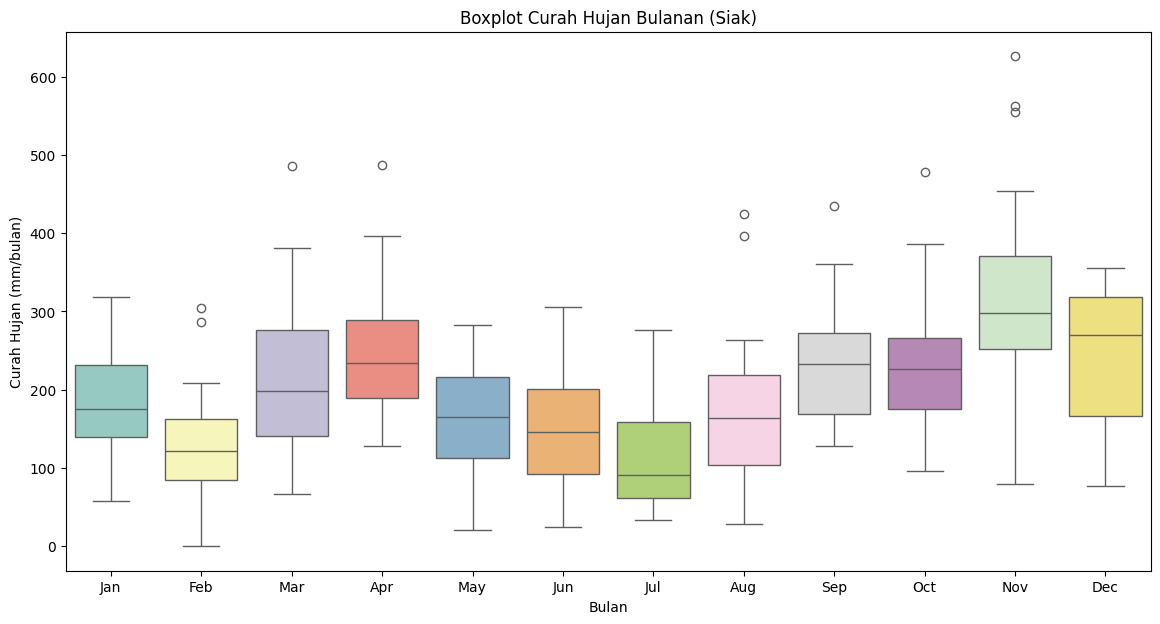

<ipython-input-9-ac28d880ff18>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Month', y='Rainfall', palette='Set3')


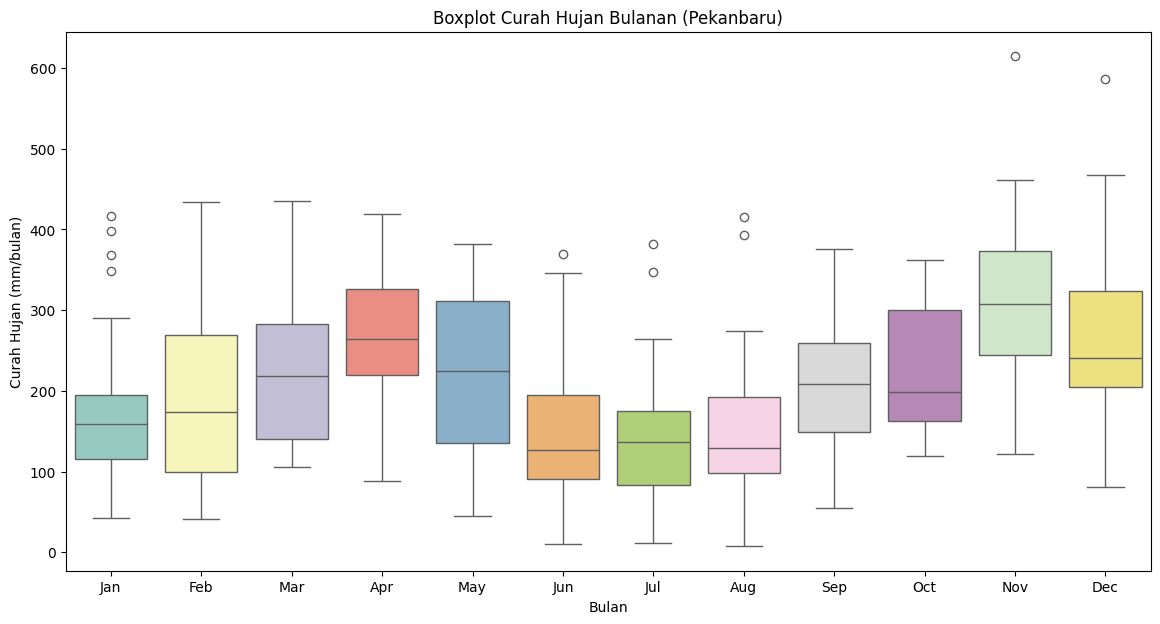

<ipython-input-9-ac28d880ff18>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Month', y='Rainfall', palette='Set3')


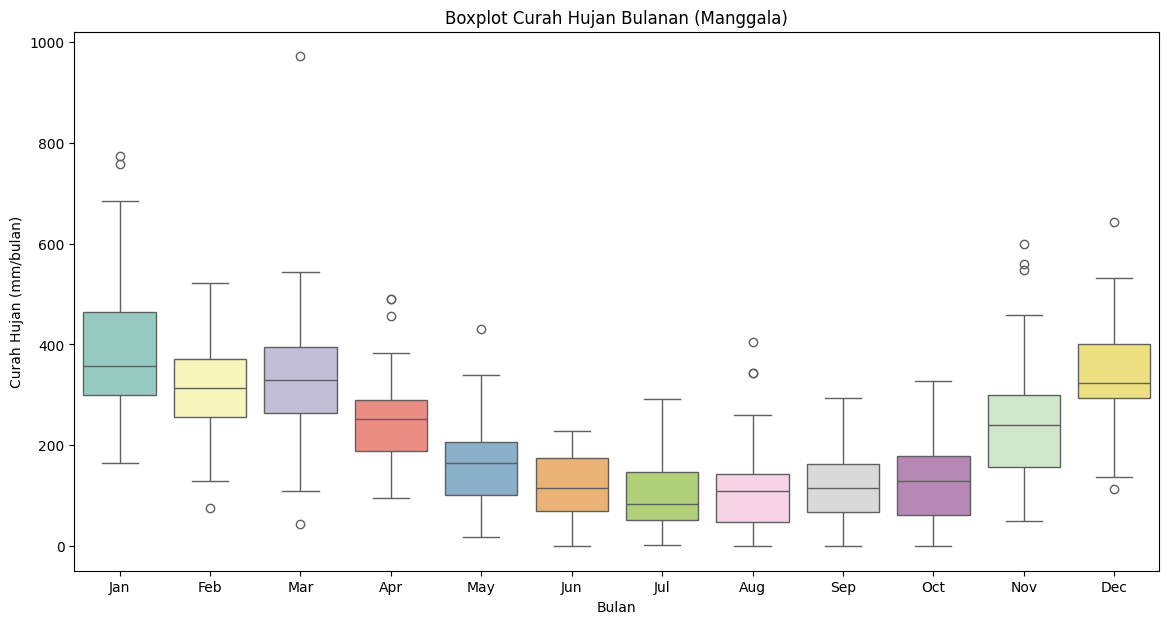

<ipython-input-9-ac28d880ff18>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Month', y='Rainfall', palette='Set3')


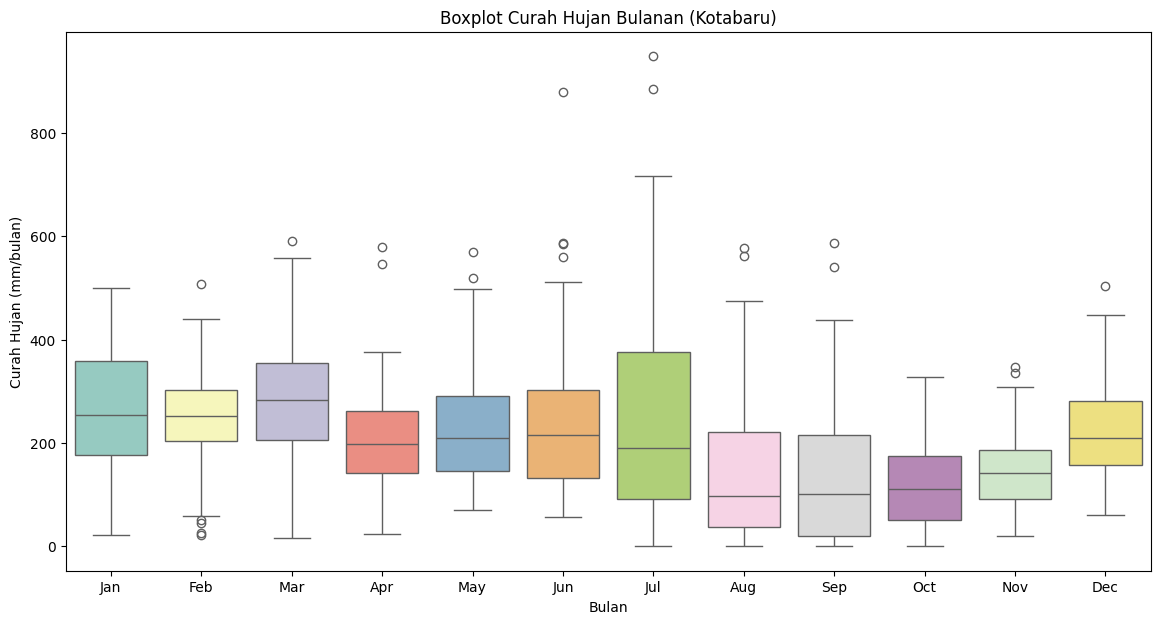

In [ ]:
for name, df in zip(['Siak','Pekanbaru', 'Manggala', 'Kotabaru'], [df1_long, df2_long, df3_long, df4_long]):
    plt.figure(figsize=(14, 7))
    sns.boxplot(data=df, x='Month', y='Rainfall', palette='Set3')
    plt.title(f'Boxplot Curah Hujan Bulanan ({name})')
    plt.xlabel('Bulan')
    plt.ylabel('Curah Hujan (mm/bulan)')
    plt.xticks(range(12), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
    plt.show()

In [ ]:
def detect_outliers(df, group_col='Month', value_col='Rainfall'):
    # Hitung Q1 dan Q3 untuk setiap grup (bulan)
    stats = df.groupby(group_col)[value_col].quantile([0.25, 0.75]).unstack()

    # Ubah nama kolom untuk Q1 dan Q3
    stats.columns = ['Q1', 'Q3']

    # Hitung IQR
    stats['IQR'] = stats['Q3'] - stats['Q1']

    # Gabungkan kembali ke DataFrame asli
    df = df.merge(stats, left_on=group_col, right_index=True)

    # Hitung batas bawah dan batas atas untuk outlier
    df['Lower Bound'] = df['Q1'] - 1.5 * df['IQR']
    df['Upper Bound'] = df['Q3'] + 1.5 * df['IQR']

    # Tandai outlier
    df['Outlier'] = (df[value_col] < df['Lower Bound']) | (df[value_col] > df['Upper Bound'])

    # Hitung jumlah outlier
    outlier_count = df['Outlier'].sum()
    return df, outlier_count

# Hitung dan tampilkan jumlah outlier untuk setiap DataFrame
for name, df in zip(['Siak','Pekanbaru', 'Manggala', 'Kotabaru'], [df1_long, df2_long, df3_long,df4_long]):
    df_with_outliers, outlier_count = detect_outliers(df)
    print(f"Jumlah data outlier pada {name}: {outlier_count}")


Jumlah data outlier pada Siak: 11
Jumlah data outlier pada Pekanbaru: 11
Jumlah data outlier pada Manggala: 17
Jumlah data outlier pada Kotabaru: 23


## 3. Gap Filling

In [ ]:
# Cek missing value
print(df1_long.isnull().sum())
print(df2_long.isnull().sum())
print(df3_long.isnull().sum())
print(df4_long.isnull().sum())


Year        0
Month       0
Rainfall    4
Date        0
dtype: int64
Year        0
Month       0
Rainfall    5
Date        0
dtype: int64
Year          0
Month         0
Rainfall    291
Date          0
dtype: int64
Year          0
Month         0
Rainfall    164
Date          0
dtype: int64


# III. Filter Rain Days by Criteria

*Rainfall > 150 mm per month*







In [ ]:
# Filter data dengan curah hujan di atas 150 mm
filtered_data = {}
for name, df in zip(['Siak', 'Pekanbaru', 'Manggala', 'Kotabaru'], [df1_long, df2_long, df3_long,df4_long]):
    filtered_data[name] = df[df['Rainfall'] > 150]


In [ ]:
# Proses untuk menambahkan kolom tahun dan bulan
for name, df in filtered_data.items():
    df['year'] = df['Date'].dt.year
    df['month'] = df['Date'].dt.month

    # Pivot table untuk menghitung jumlah kejadian per bulan dan per tahun
    rain_counts = df.pivot_table(index='year', columns='month', values='Date', aggfunc='count', fill_value=0)
    rain_counts['Total'] = rain_counts.sum(axis=1)  # Kolom 'Total' untuk jumlah kejadian setiap tahun
    monthly_totals = rain_counts.sum(axis=0)  # Jumlah kejadian per bulan
    monthly_totals.name = 'Total'

    rain_counts.loc['Total'] = monthly_totals
    filtered_data[name] = rain_counts  # Menyimpan hasil pivot dalam dictionary


<ipython-input-17-10b10cc2b69f>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['year'] = df['Date'].dt.year
<ipython-input-17-10b10cc2b69f>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['month'] = df['Date'].dt.month
<ipython-input-17-10b10cc2b69f>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexi

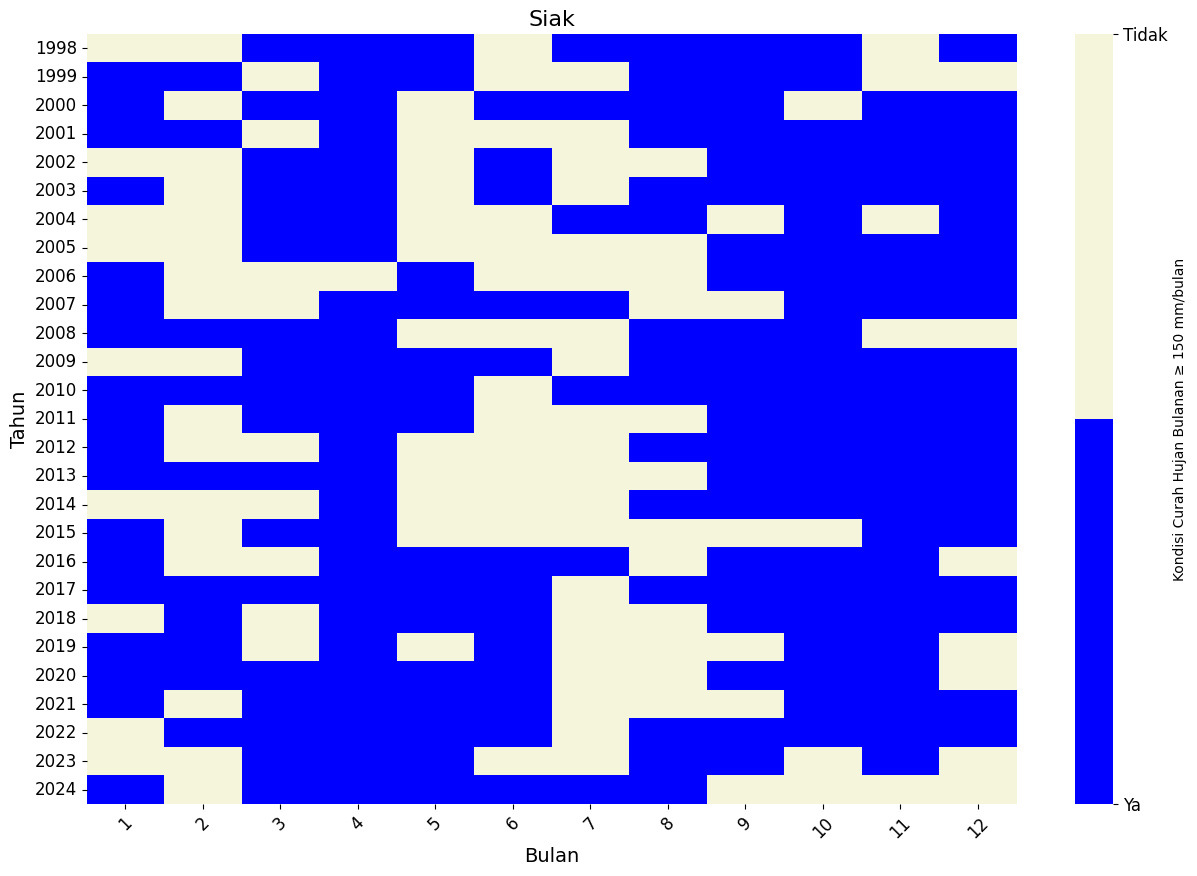

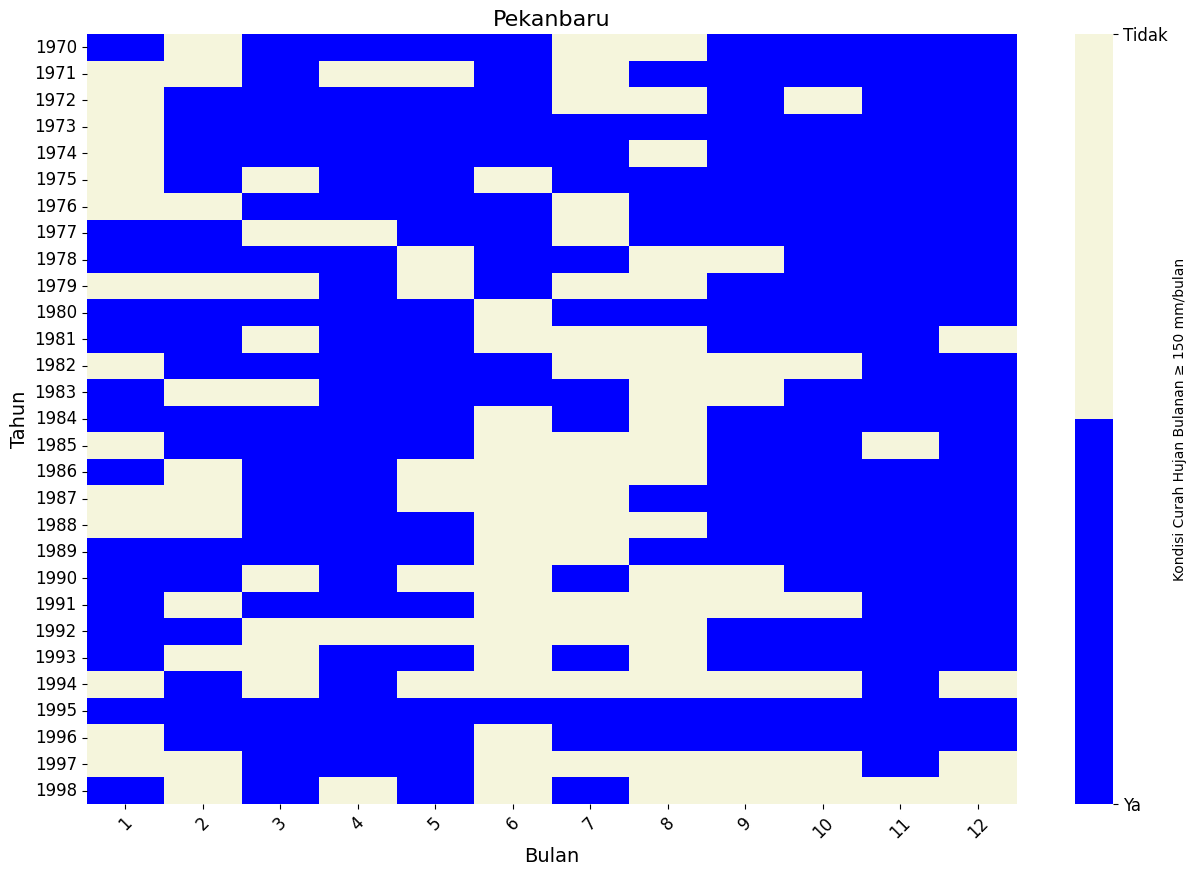

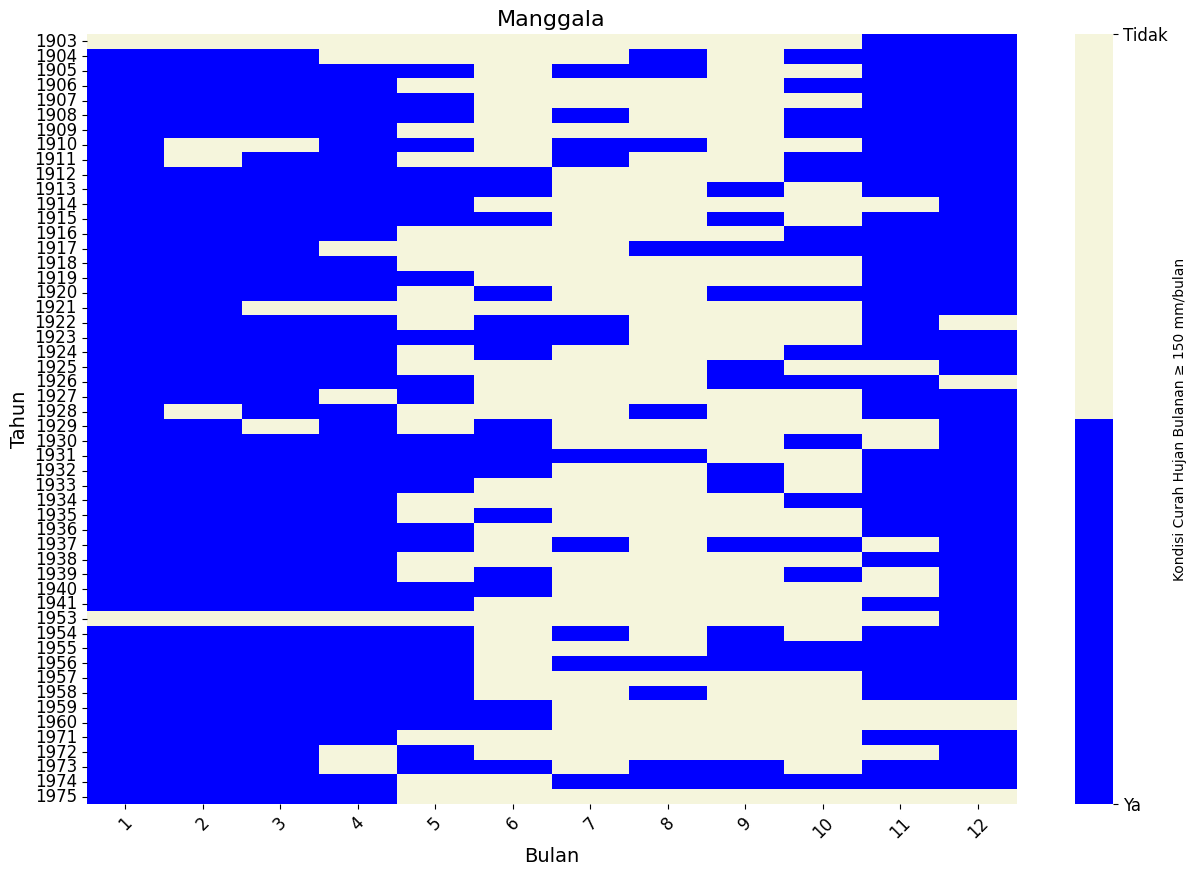

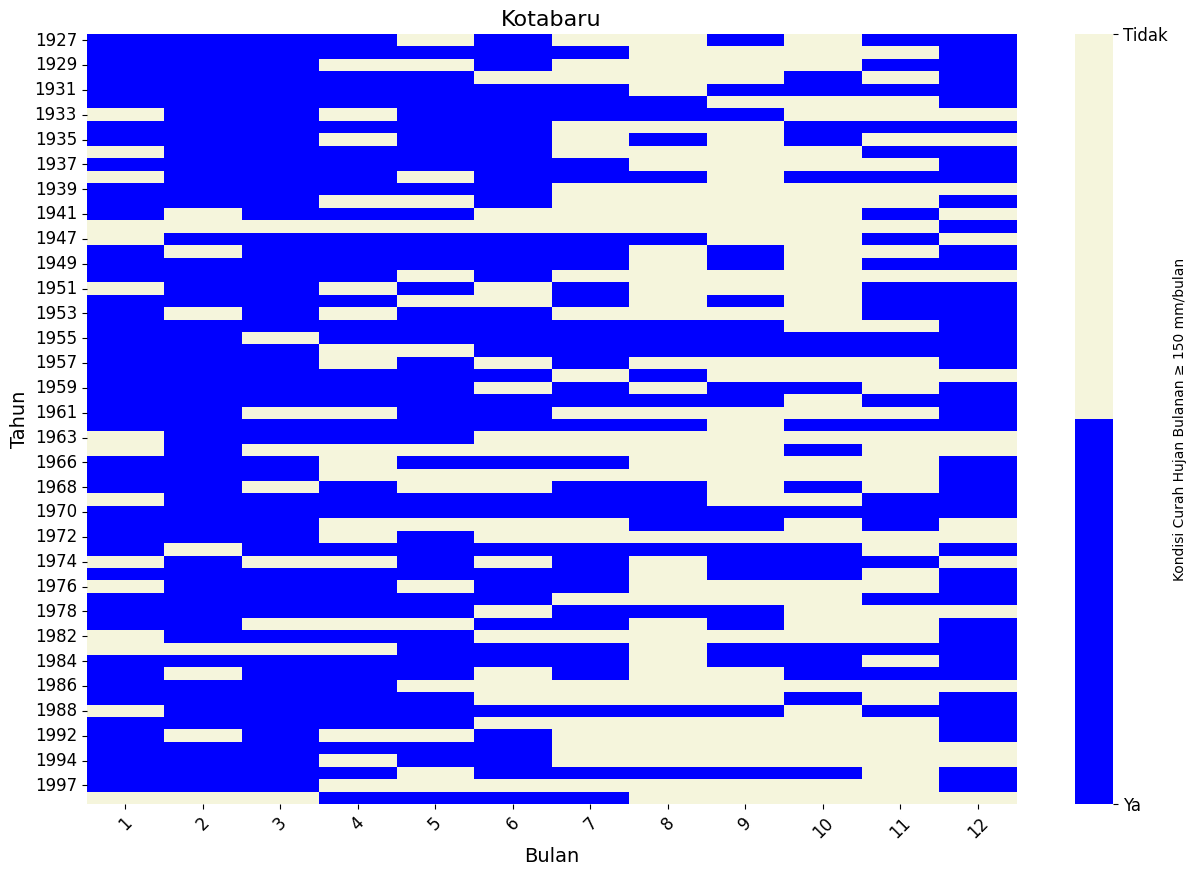

In [ ]:

for name, rain_counts in filtered_data.items():
    # Exclude the 'Total' column and the 'Total' row
    heatmap_data = rain_counts.drop(['Total'], axis=1)  # Drop the 'Total' column
    heatmap_data = heatmap_data.drop(['Total'], axis=0)  # Drop the 'Total' row

    # Define a custom colormap with two colors: krem and biru muda (light blue)
    cmap = ListedColormap(["#f5f5dc", "#0000ff"])  # Krem for "Tidak" and light blue for "Ya"

    # Create the heatmap
    plt.figure(figsize=(15, 10))  # Adjust figure size as needed
    ax = sns.heatmap(
        heatmap_data,
        cmap=cmap,  # Apply the custom colormap
        annot=False,  # Disable annotations
        cbar_kws={"ticks": [0, 1], "label": "Kondisi Curah Hujan Bulanan ≥ 150 mm/bulan"}  # Set ticks for colorbar and add label
    )

    # Add labels to colorbar
    colorbar = ax.collections[0].colorbar
    colorbar.set_ticklabels(["Tidak", "Ya"])  # Set colorbar labels for "Tidak" and "Ya"

    # Customize the colorbar to have a smooth legend inside the scale
    colorbar.ax.invert_yaxis()  # Ensure that the color scale follows the correct order
    colorbar.ax.tick_params(labelsize=12)  # Adjust label size of the ticks

    # Set title and labels
    plt.title(f"{name}", fontsize=16)
    plt.xlabel("Bulan", fontsize=14)
    plt.ylabel("Tahun", fontsize=14)
    plt.xticks(rotation=45, fontsize=12)  # Rotate x-axis labels for better readability
    plt.yticks(fontsize=12)  # Adjust y-axis tick size
    plt.show()


<ipython-input-38-a31ffefb7f4c>:79: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.95])


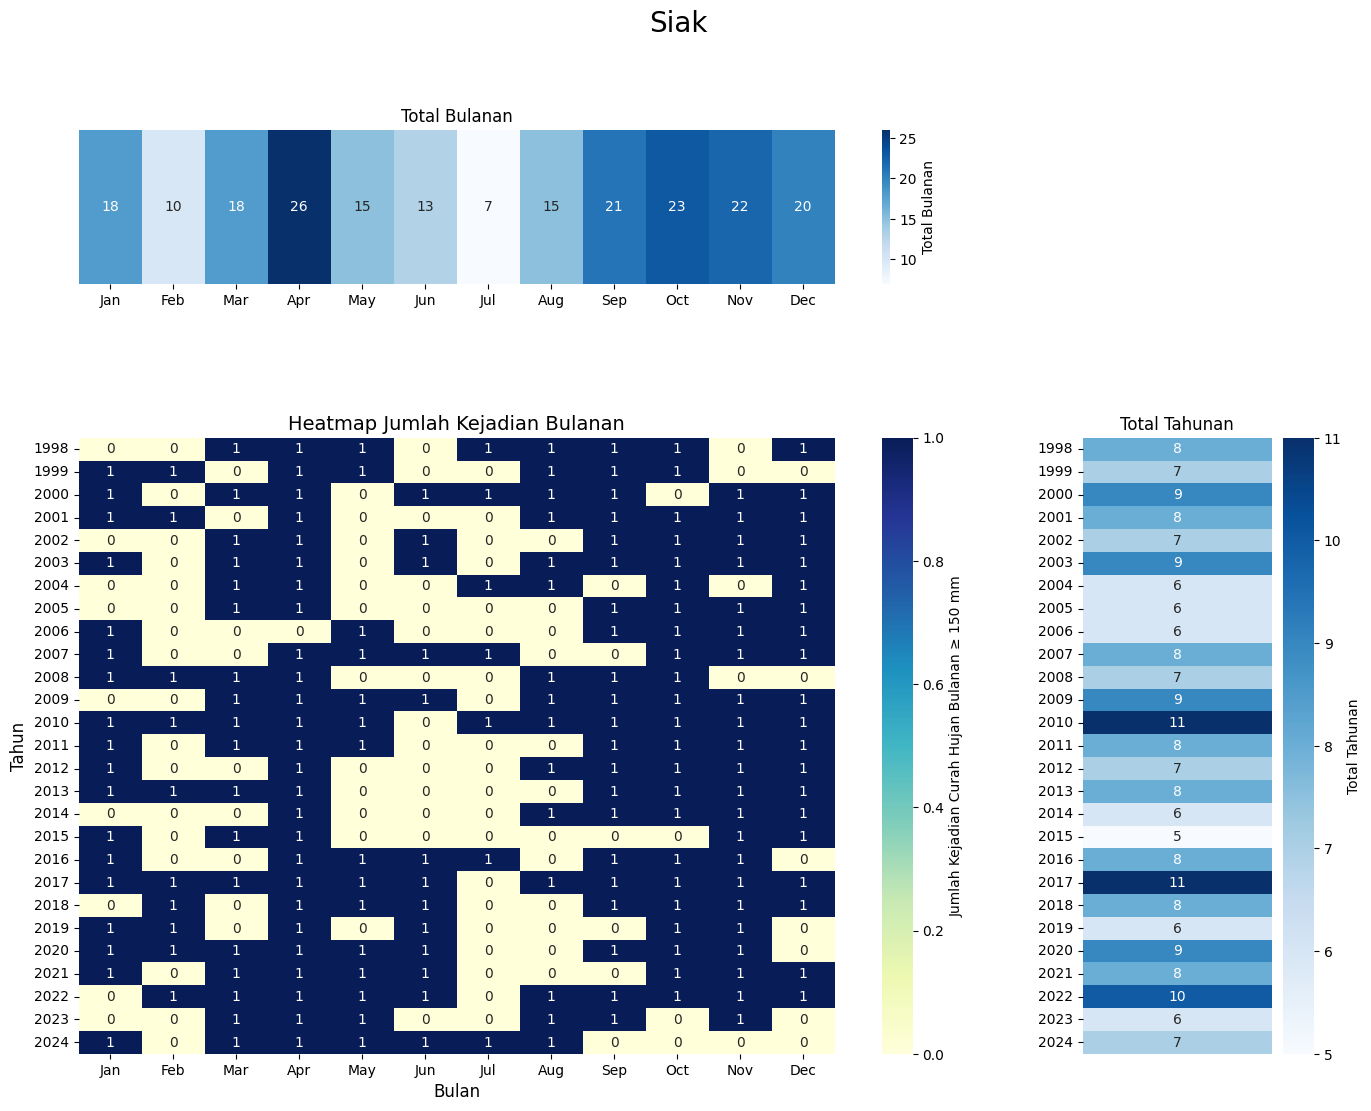

<ipython-input-38-a31ffefb7f4c>:79: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.95])


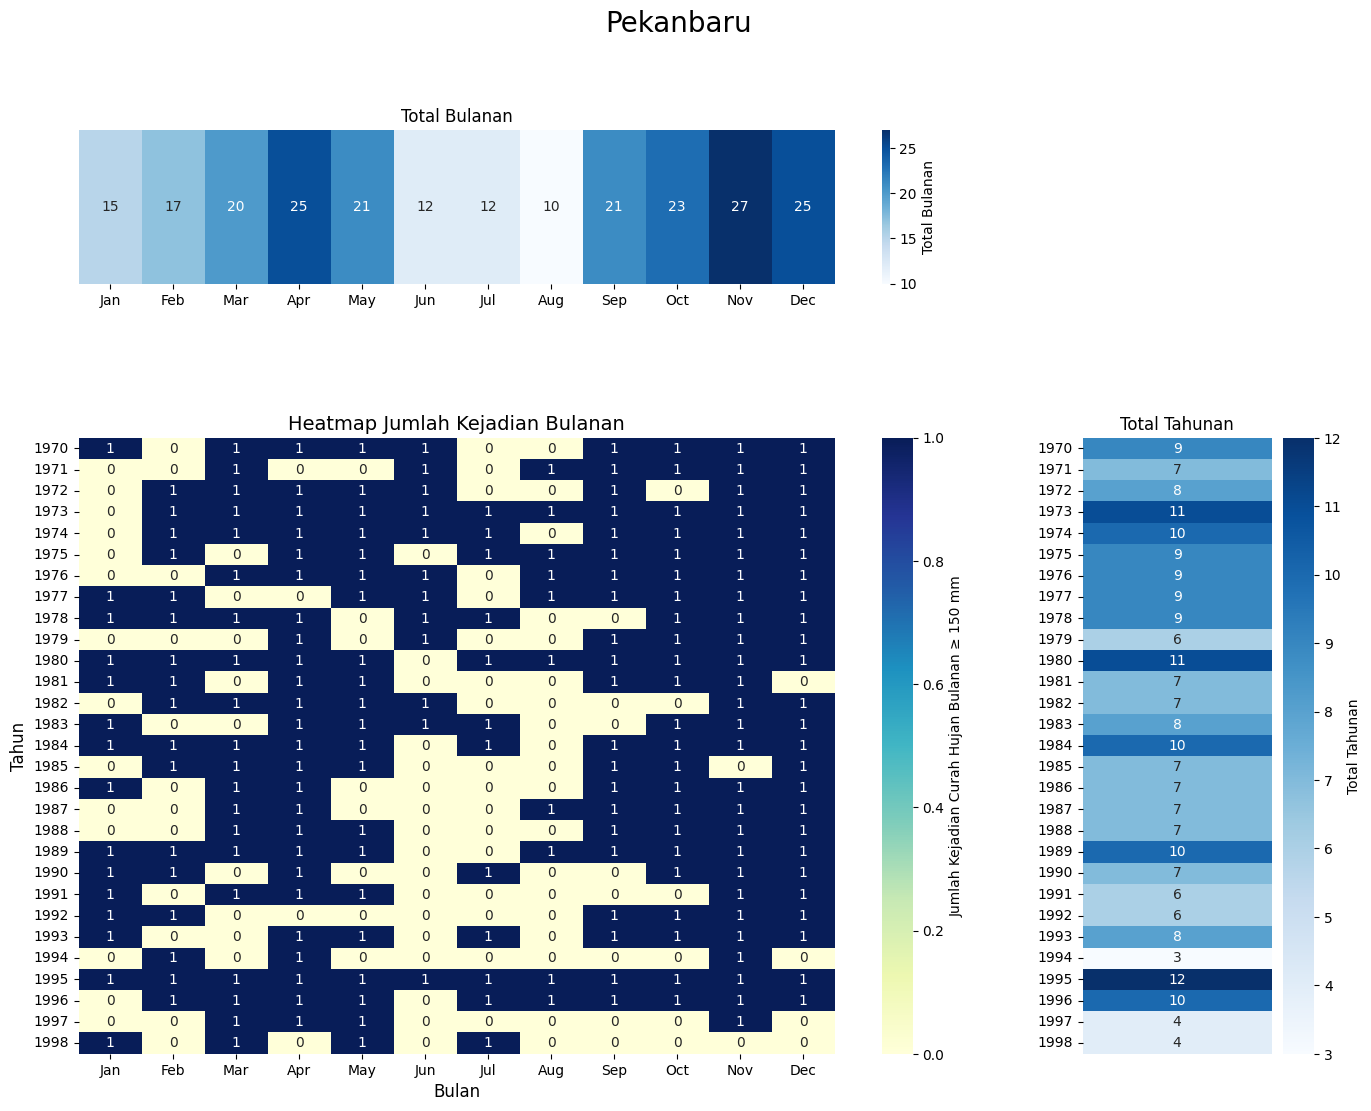

<ipython-input-38-a31ffefb7f4c>:79: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.95])


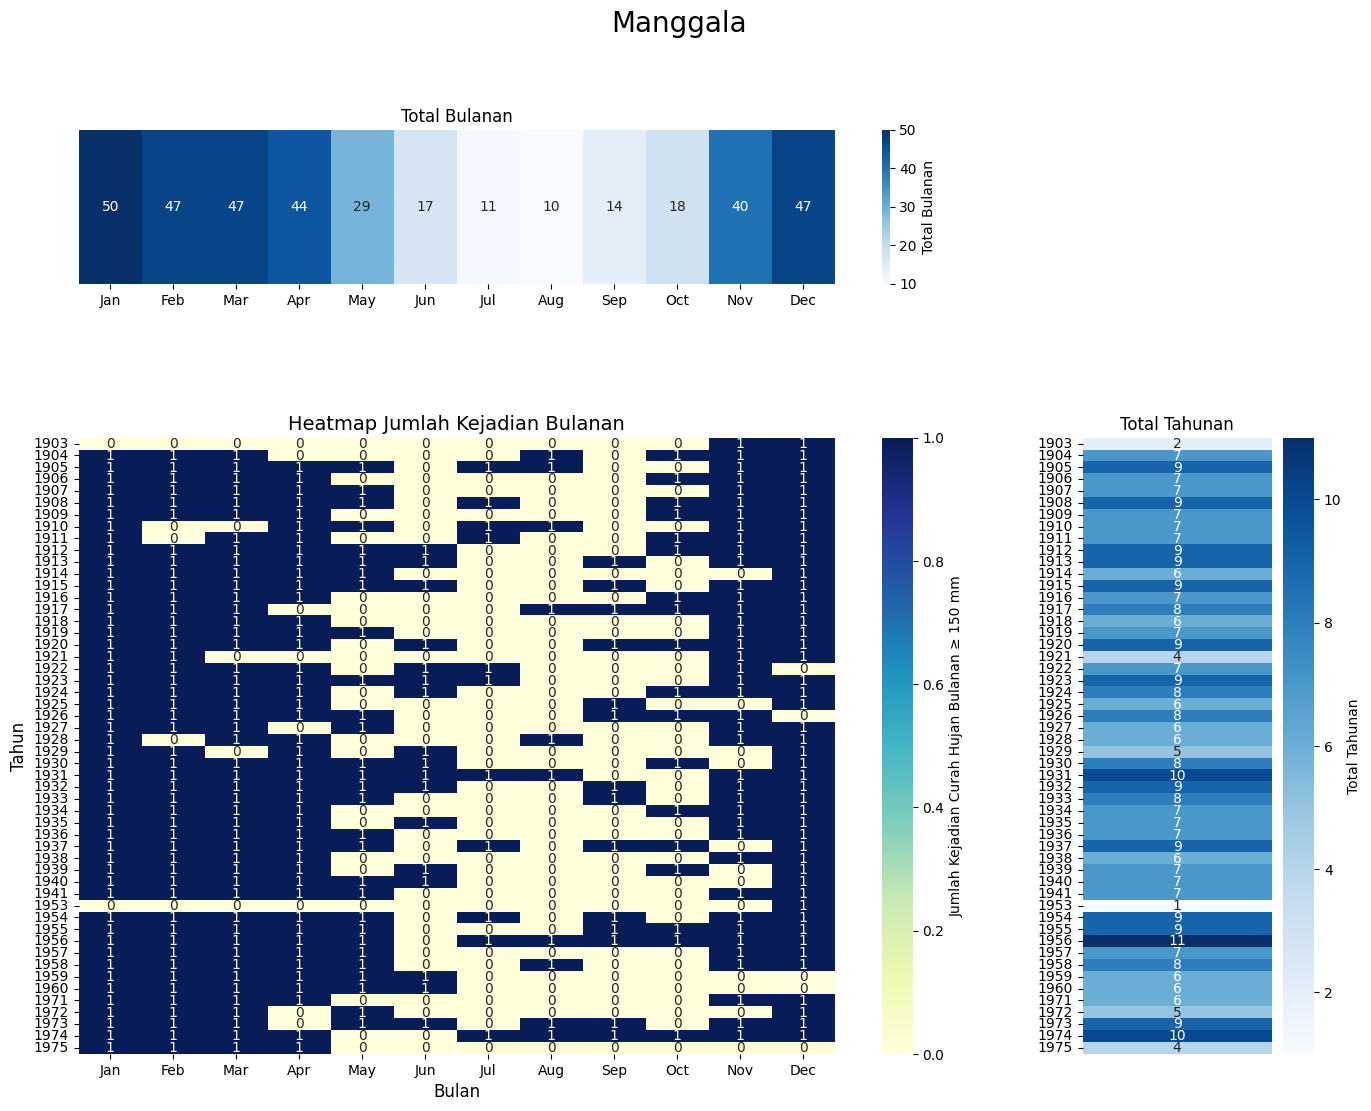

<ipython-input-38-a31ffefb7f4c>:79: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.95])


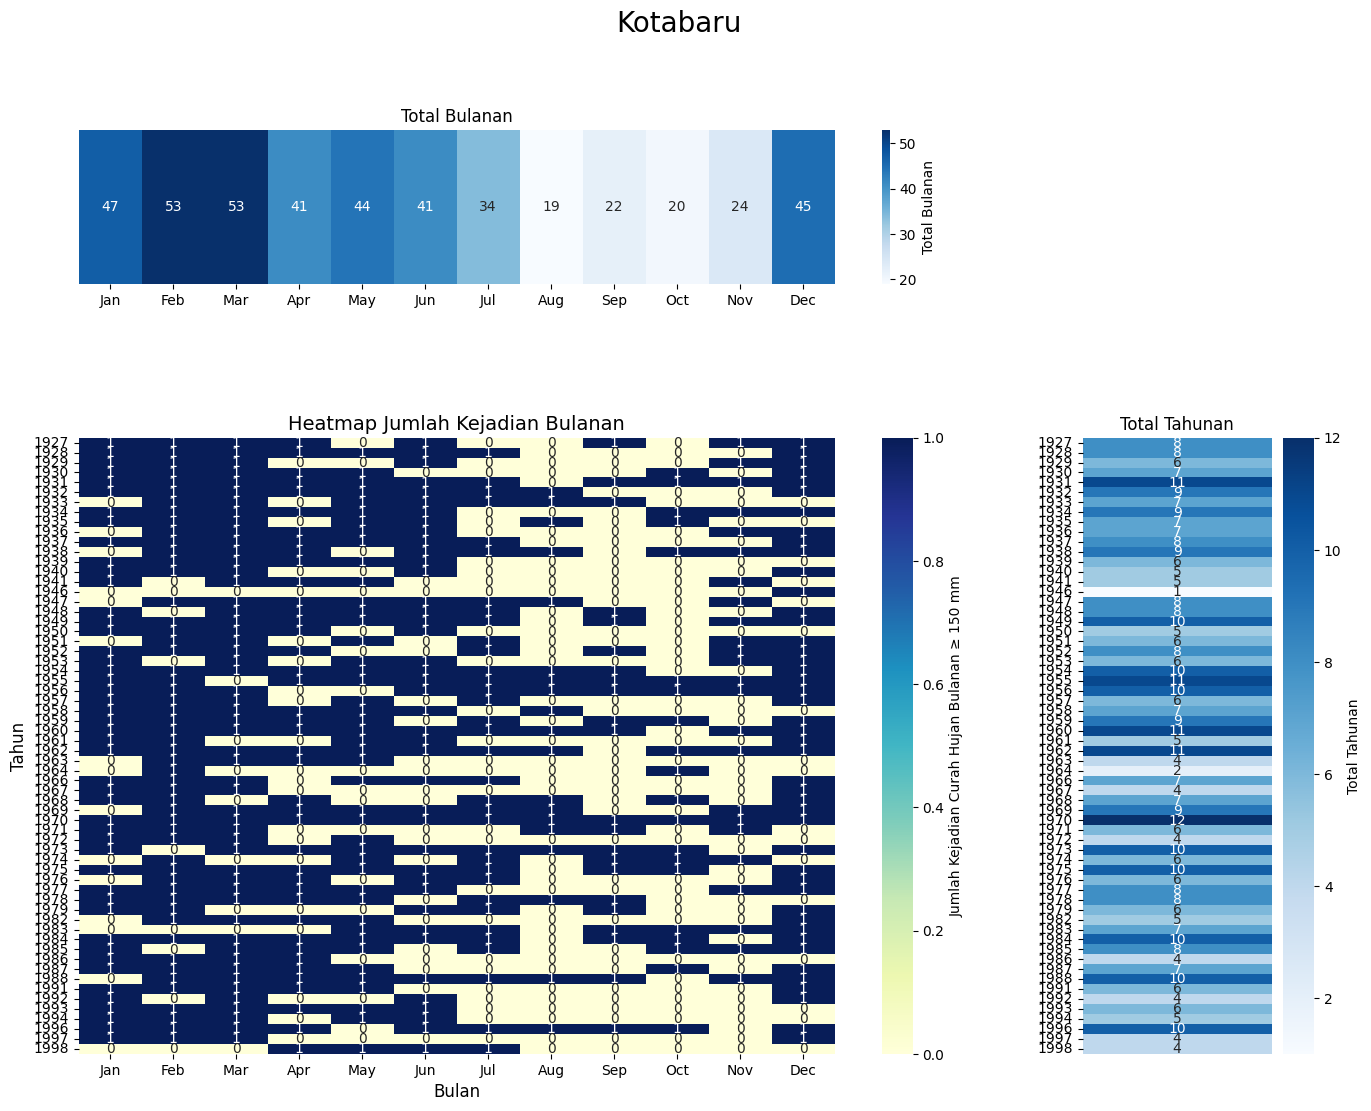

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# Data preparation (mengikuti contoh Anda)
for name, rain_counts in filtered_data.items():
    # Pastikan data "Total" tidak diikutsertakan
    heatmap_data = rain_counts.drop(['Total'], axis=1)  # Hapus kolom 'Total'
    heatmap_data = heatmap_data.drop(['Total'], axis=0)  # Hapus baris 'Total'

    # Tambahkan total untuk baris (tahun) dan kolom (bulan)
    heatmap_data['Total'] = heatmap_data.sum(axis=1)  # Total tahunan
    monthly_totals = heatmap_data.sum(axis=0)  # Total bulanan
    monthly_totals.name = 'Total'
    heatmap_data.loc['Total'] = monthly_totals  # Tambahkan total bulanan

    # Pisahkan data
    monthly_data = heatmap_data.iloc[:-1, :-1]  # Data bulanan
    yearly_totals = heatmap_data.iloc[:-1, -1]  # Total tahunan
    monthly_totals = heatmap_data.iloc[-1, :-1]  # Total bulanan

    # Penamaan bulan
    months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

    # Figure untuk tiga heatmap
    fig = plt.figure(figsize=(16, 12))
    gs = GridSpec(2, 2, width_ratios=[4, 1], height_ratios=[1, 4], hspace=0.4, wspace=0.1)

    # 1. Heatmap utama (jumlah kejadian bulanan per tahun)
    ax_main = fig.add_subplot(gs[1, 0])
    sns.heatmap(
        monthly_data,
        cmap="YlGnBu",
        annot=True,
        fmt="d",
        cbar_kws={"label": "Jumlah Kejadian Curah Hujan Bulanan ≥ 150 mm"},
        ax=ax_main,
        xticklabels=months,
        yticklabels=monthly_data.index.astype(int)
    )
    ax_main.set_xlabel("Bulan", fontsize=12)
    ax_main.set_ylabel("Tahun", fontsize=12)
    ax_main.set_title("Heatmap Jumlah Kejadian Bulanan", fontsize=14)

    # 2. Heatmap total tahunan (sebelah kanan)
    ax_year = fig.add_subplot(gs[1, 1], sharey=ax_main)
    yearly_data = yearly_totals.values.reshape(-1, 1)  # Ubah jadi matriks kolom
    sns.heatmap(
        yearly_data,
        cmap="Blues",
        annot=True,
        fmt="d",
        cbar_kws={"label": "Total Tahunan"},
        ax=ax_year,
        xticklabels=False,
        yticklabels=yearly_totals.index.astype(int)
    )
    ax_year.set_title("Total Tahunan", fontsize=12)

    # 3. Heatmap total bulanan (di atas)
    ax_month = fig.add_subplot(gs[0, 0], sharex=ax_main)
    monthly_data_reshaped = monthly_totals.values.reshape(1, -1)  # Ubah jadi matriks baris
    sns.heatmap(
        monthly_data_reshaped,
        cmap="Blues",
        annot=True,
        fmt="d",
        cbar_kws={"label": "Total Bulanan"},
        ax=ax_month,
        xticklabels=months,
        yticklabels=False
    )
    ax_month.set_title("Total Bulanan", fontsize=12)

    # Menyempurnakan layout
    plt.suptitle(f"{name}", fontsize=20)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


## Jumlah kejadian berdasarkan Tahun


<ipython-input-48-5a8f3dcd4dfa>:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


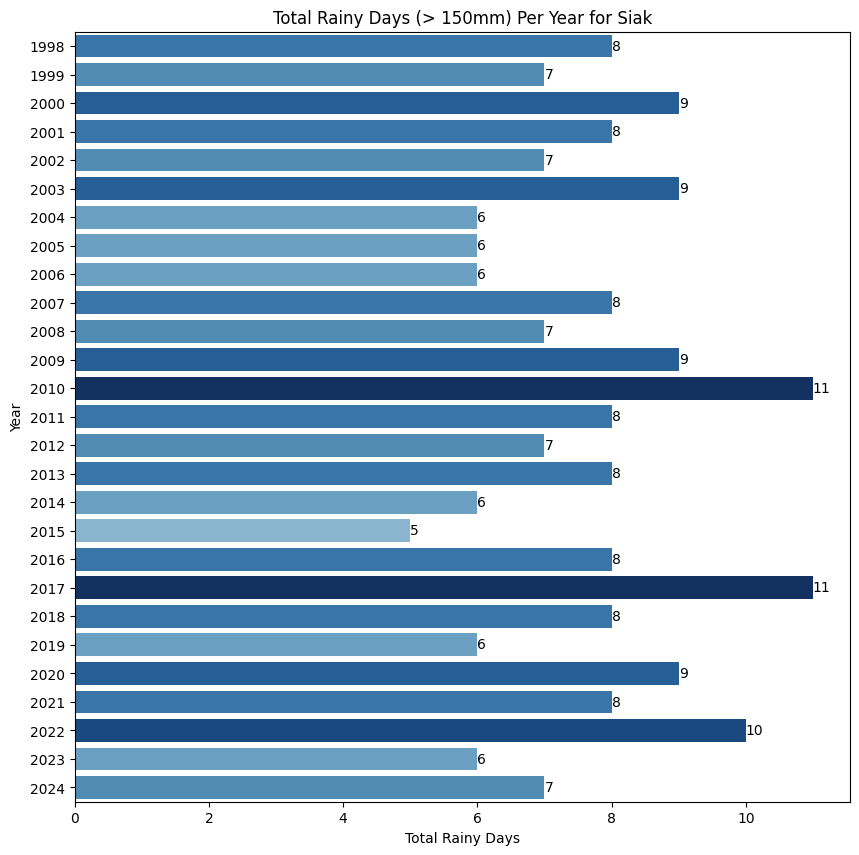

<ipython-input-48-5a8f3dcd4dfa>:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


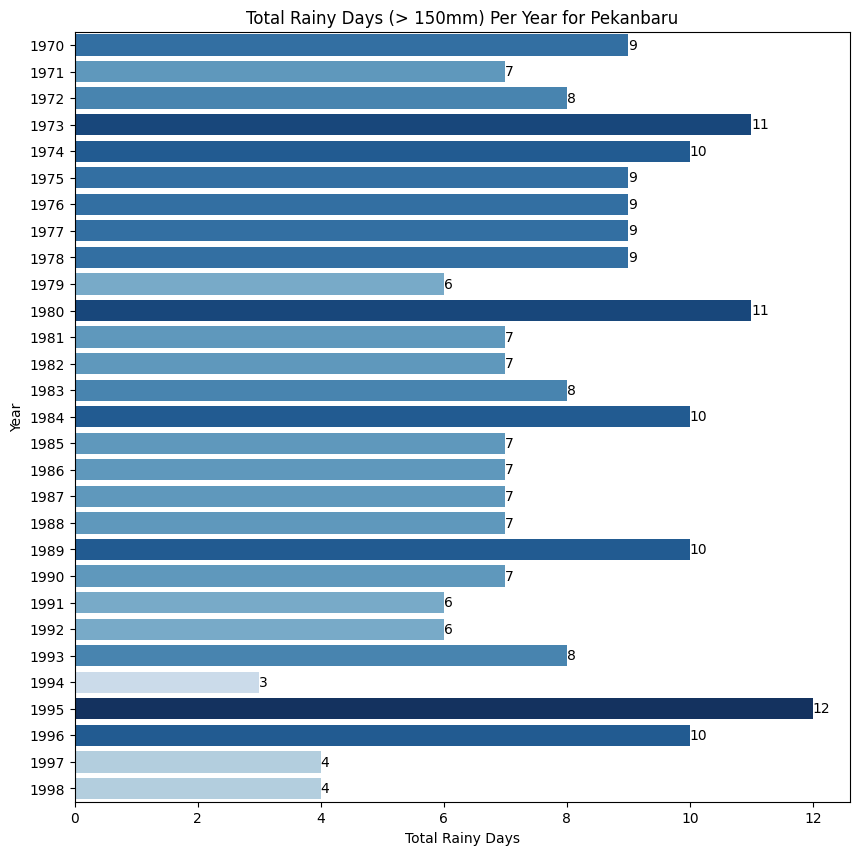

<ipython-input-48-5a8f3dcd4dfa>:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


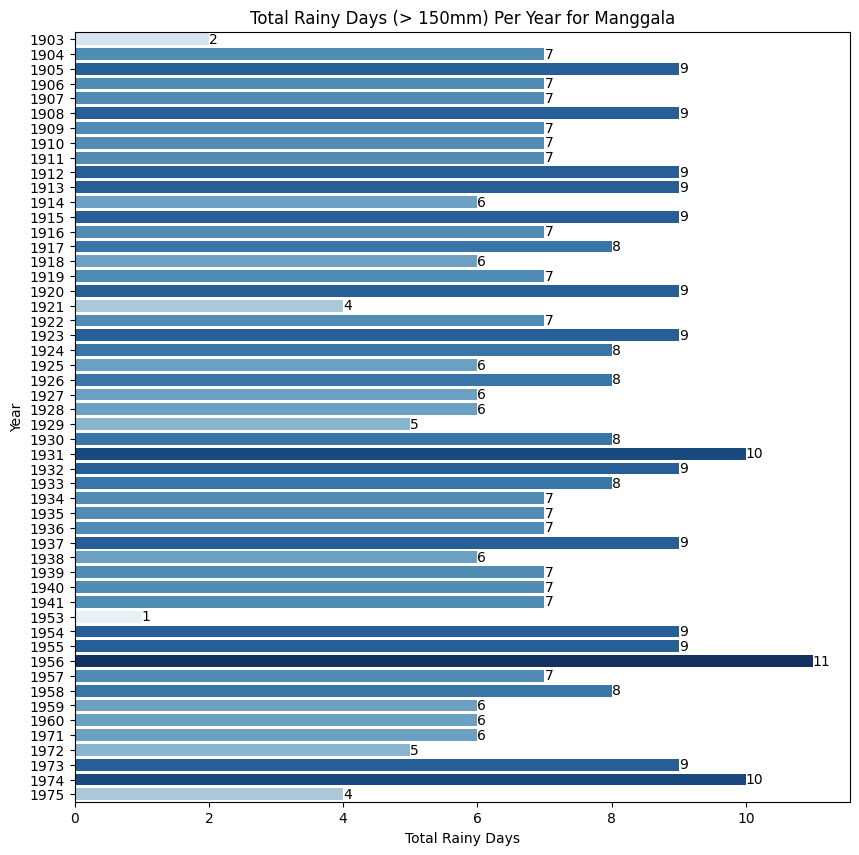

<ipython-input-48-5a8f3dcd4dfa>:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


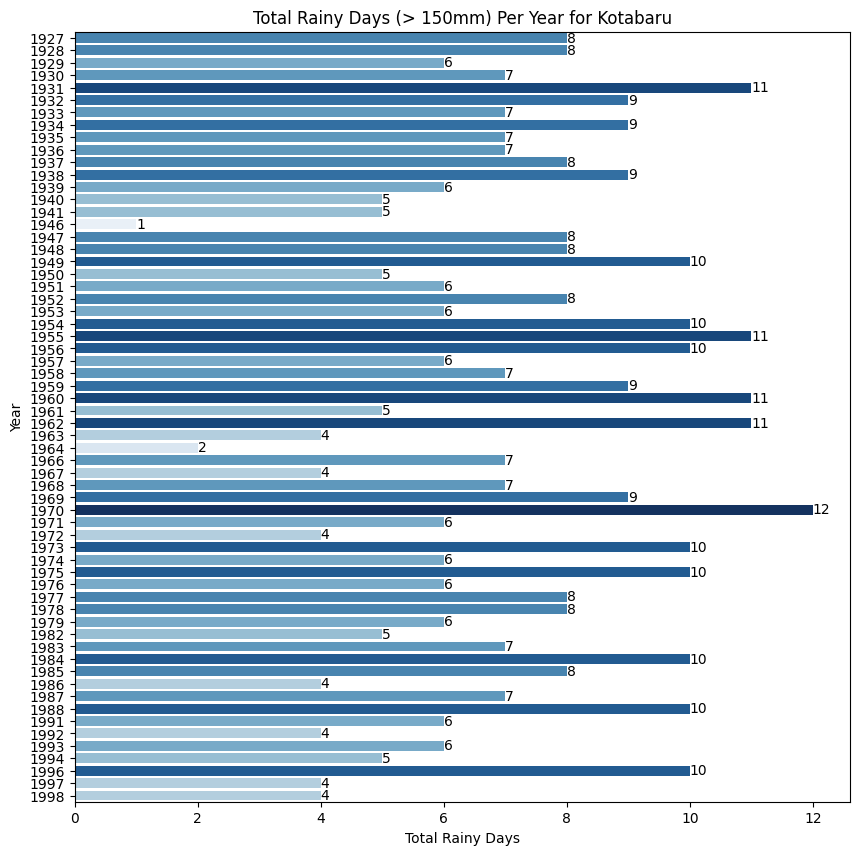

In [ ]:
for name, rain_counts in filtered_data.items():
    # Exclude the 'Total' column and the 'Total' row
    heatmap_data = rain_counts.drop(['Total'], axis=1)  # Drop the 'Total' column
    heatmap_data = heatmap_data.drop(['Total'], axis=0)  # Drop the 'Total' row

    # Calculate the total number of rainy days (>150mm) for each year
    yearly_totals = heatmap_data.sum(axis=1)  # Sum across columns for each row

    # Create a horizontal barplot
    plt.figure(figsize=(10, 10))  # Adjust figure size as needed
    cmap = sns.color_palette("Blues", as_cmap=True)
    ax = sns.barplot(
        x=yearly_totals.values,  # Sum of rainy days for each year
        y=yearly_totals.index,   # Year labels (row names)
        palette=[cmap(i / max(yearly_totals.values)) for i in yearly_totals.values],  # Membuat palet warna dinamis
        orient="h"               # Horizontal orientation
    )

    # Add labels to each bar
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f")  # Format as integers

    plt.xlabel("Total Rainy Days")
    plt.ylabel("Year")
    plt.title(f"Total Rainy Days (> 150mm) Per Year for {name}")
    plt.show()

## Jumlah Kejadian berdasarkan Bulan

<ipython-input-44-7dd897e82606>:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


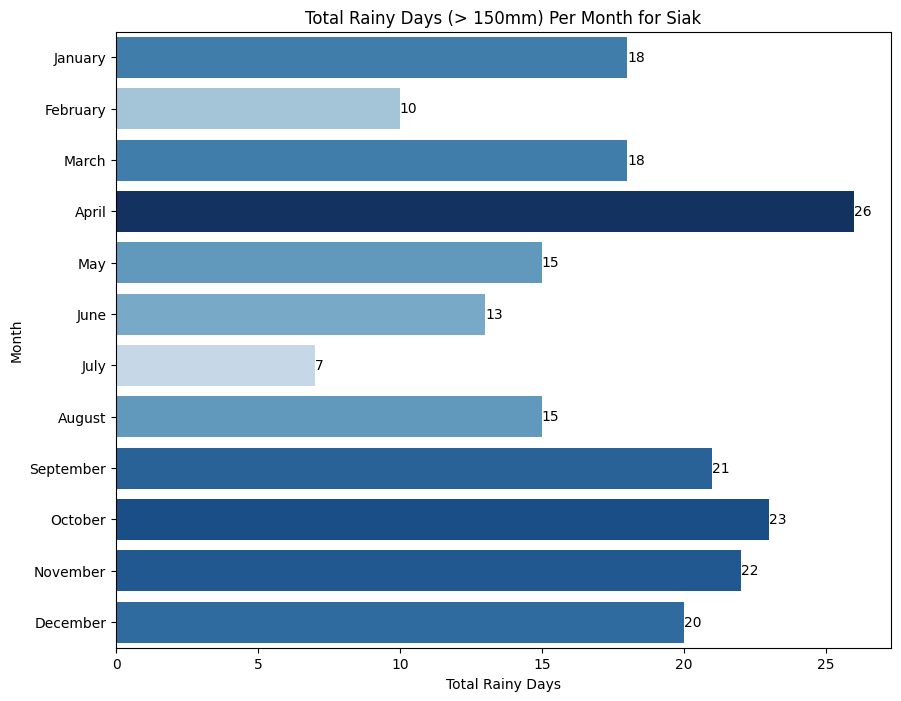

<ipython-input-44-7dd897e82606>:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


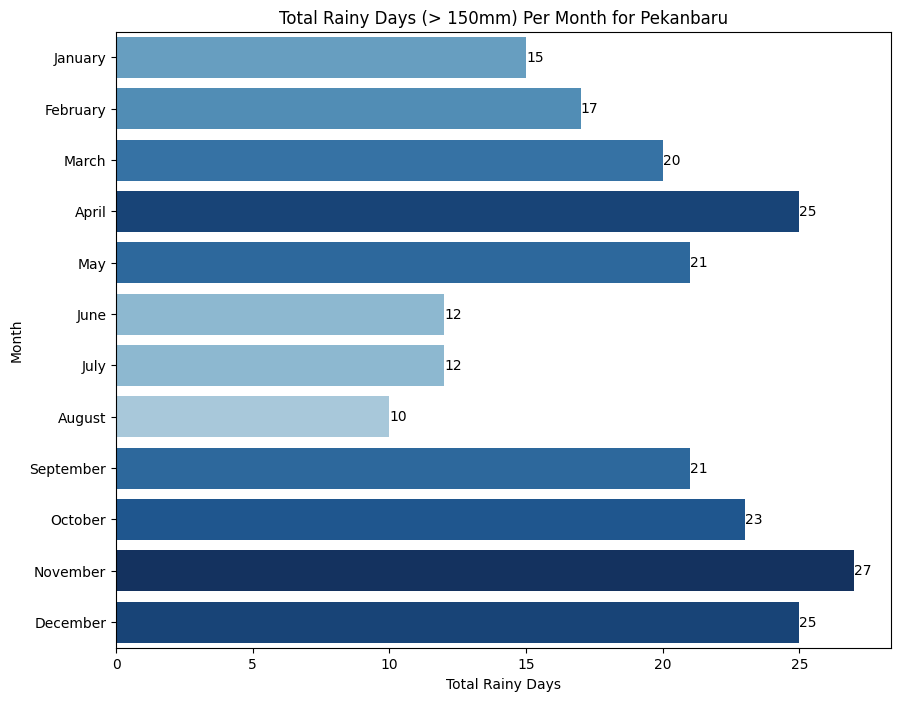

<ipython-input-44-7dd897e82606>:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


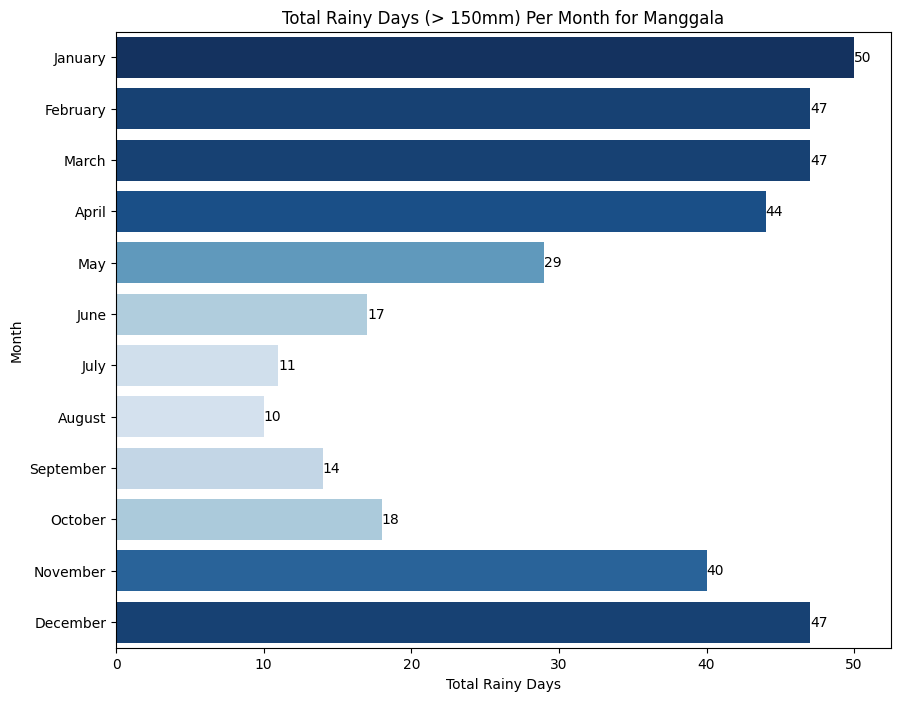

<ipython-input-44-7dd897e82606>:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


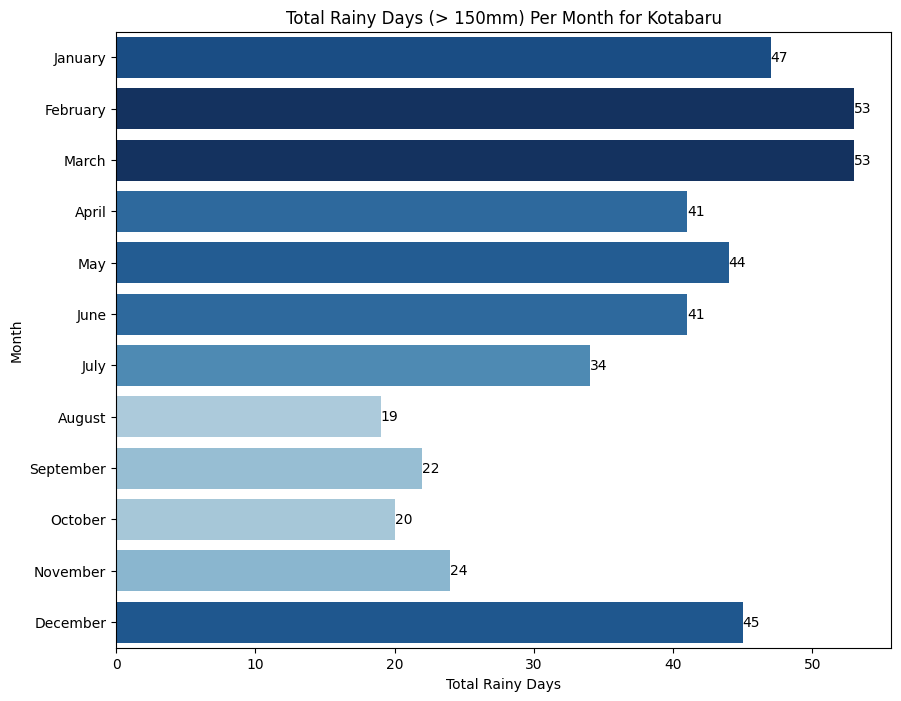

In [ ]:
for name, rain_counts in filtered_data.items():
    # Exclude the 'Total' column and the 'Total' row
    heatmap_data = rain_counts.drop(['Total'], axis=1)  # Drop the 'Total' column
    heatmap_data = heatmap_data.drop(['Total'], axis=0)  # Drop the 'Total' row

    # Calculate the total number of rainy days (>150mm) for each month
    monthly_totals = heatmap_data.sum(axis=0)  # Sum across rows for each column

    # Replace month indices with full month names
    monthly_totals.index = [calendar.month_name[int(month)] for month in monthly_totals.index]

    # Create a horizontal barplot
    plt.figure(figsize=(10, 8))  # Adjust figure size as needed
    cmap = plt.get_cmap("Blues")  # Pilih palet warna "Blues"
    max_value = monthly_totals.max()  # Cari nilai maksimum
    ax = sns.barplot(
        x=monthly_totals.values,  # Sum of rainy days for each month
        y=monthly_totals.index,   # Month labels (full names)
        palette=[cmap(i / max_value) for i in monthly_totals.values],  # Buat palet warna dinamis
        orient="h"                # Horizontal orientation
    )

    # Add labels to each bar
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f")  # Format as integers

    plt.xlabel("Total Rainy Days")
    plt.ylabel("Month")
    plt.title(f"Total Rainy Days (> 150mm) Per Month for {name}")
    plt.show()

# IV. Analisis

1.   Seasonal Trends Analysis
2.   Man-Kendall Test
3.   Corelation Analysis





# V. Visualisasi

1.   Anual Trends
2.   Seasonal Trends
3.   Frequency
4.   Monthly Heatmap
5.   Corelation Plot



## 1. Anual Trends

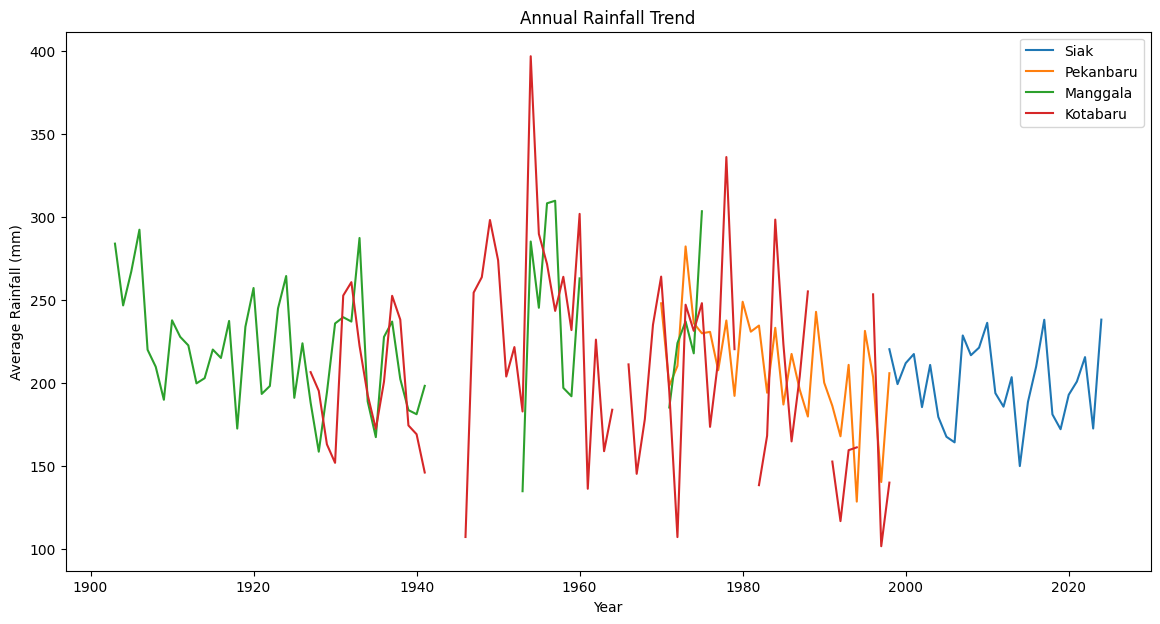

In [ ]:
# Annual trend plot untuk semua data
plt.figure(figsize=(14, 7))
for name, df in zip(['Siak','Pekanbaru', 'Manggala', 'Kotabaru'], [df1_long, df2_long, df3_long, df4_long]):
    df['Year'] = df['Date'].dt.year
    annual_trend = df.groupby('Year')['Rainfall'].mean()
    plt.plot(annual_trend.index, annual_trend.values, label=name)

plt.title('Annual Rainfall Trend')
plt.xlabel('Year')
plt.ylabel('Average Rainfall (mm)')
plt.legend()
plt.show()


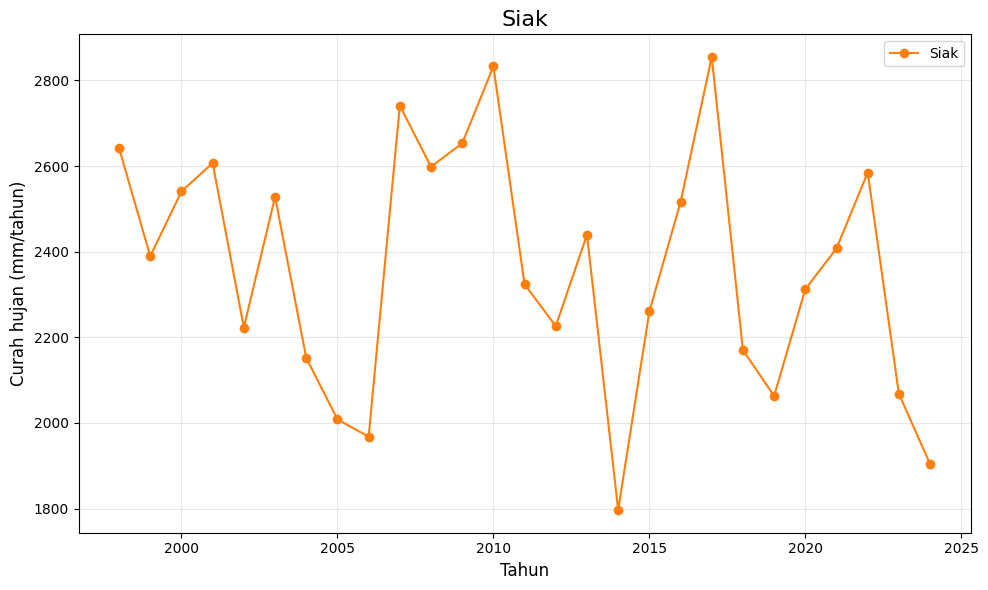

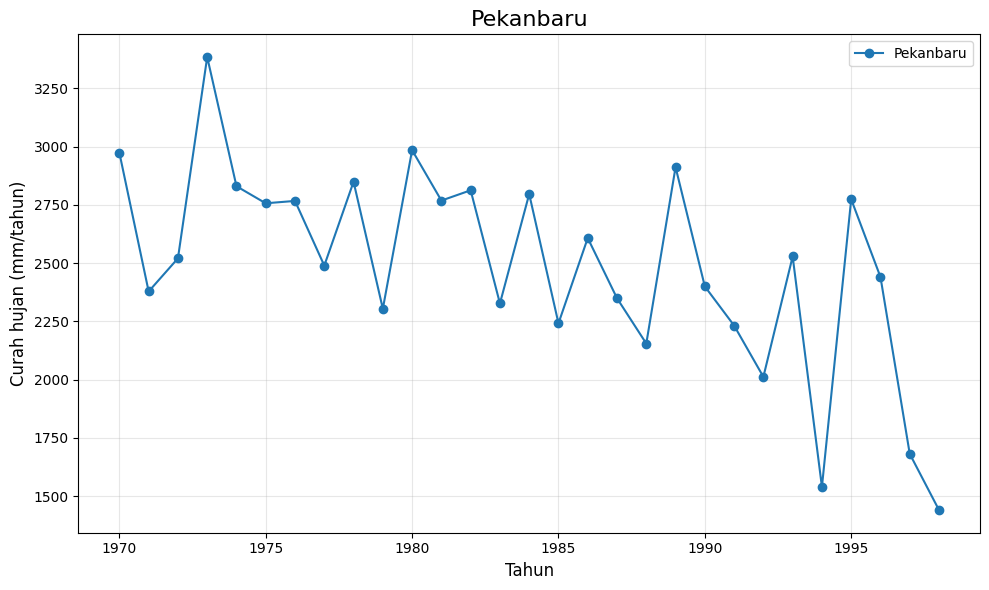

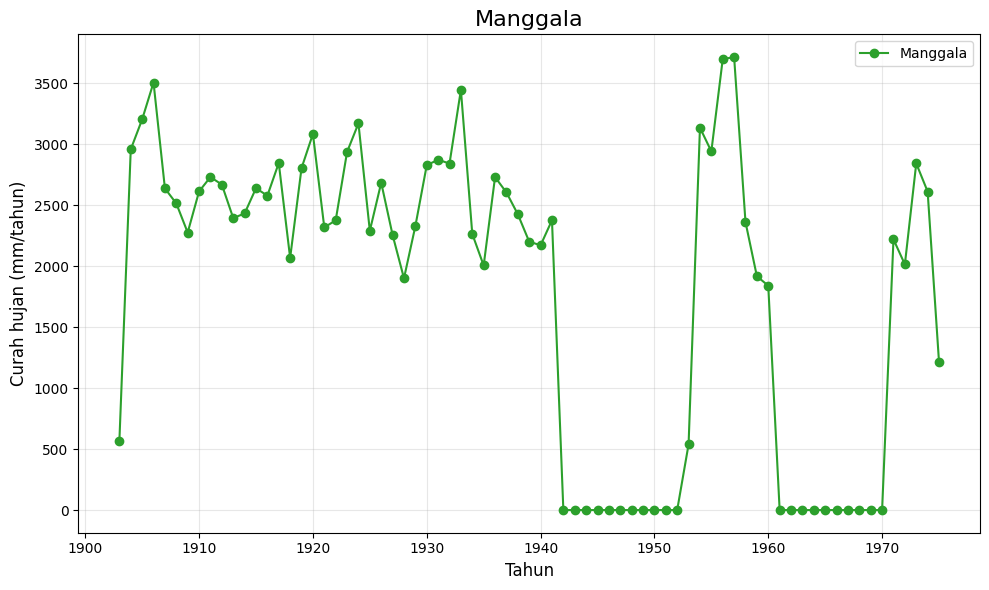

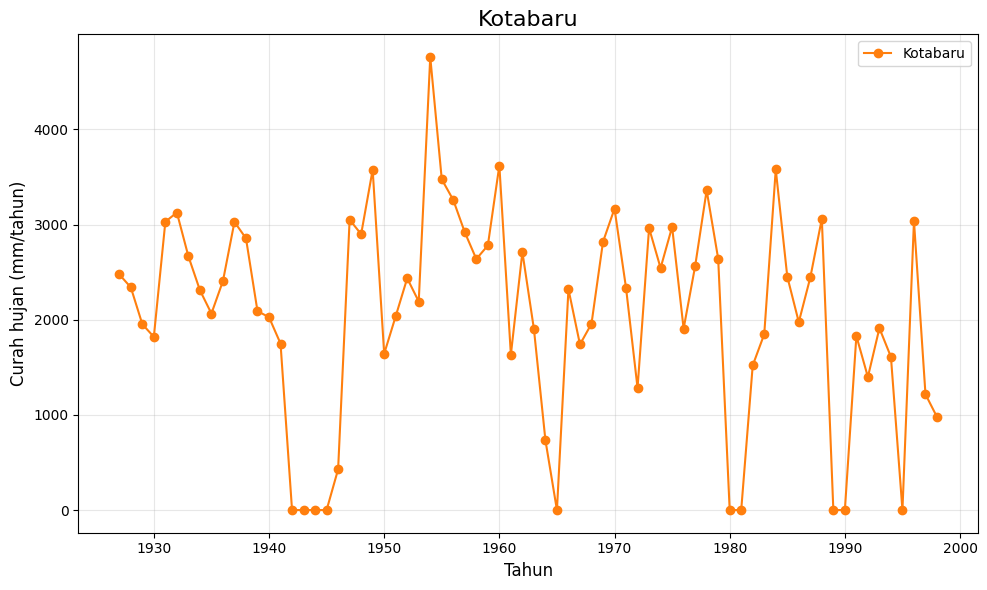

In [ ]:
# Loop untuk membuat grafik tren tahunan untuk setiap lokasi
for name, df in zip(['Siak','Pekanbaru', 'Manggala', 'Kotabaru'], [df1_long, df2_long, df3_long, df4_long]):
    # Menambahkan kolom Tahun
    df['Year'] = df['Date'].dt.year

    # Menghitung rata-rata curah hujan tahunan
    annual_trend = df.groupby('Year')['Rainfall'].sum()

    # Membuat grafik
    plt.figure(figsize=(10, 6))
    plt.plot(
        annual_trend.index,
        annual_trend.values,
        marker='o',
        label=name,
        color='tab:blue' if name == 'Pekanbaru' else 'tab:green' if name == 'Manggala' else 'tab:orange'
    )

    # Judul dan label
    plt.title(f'{name}', fontsize=16)
    plt.xlabel('Tahun', fontsize=12)
    plt.ylabel('Curah hujan (mm/tahun)', fontsize=12)
    plt.grid(alpha=0.3)  # Menambahkan grid
    plt.legend(loc='upper right', fontsize=10)

    # Menampilkan grafik
    plt.tight_layout()
    plt.show()


## 2. Seasonal Trends


<ipython-input-30-47e2b21452c0>:10: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df = df['Rainfall'].resample('M').sum()


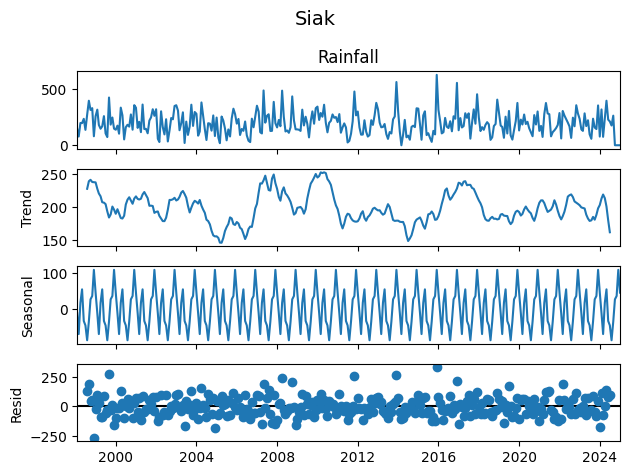

<ipython-input-30-47e2b21452c0>:10: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df = df['Rainfall'].resample('M').sum()


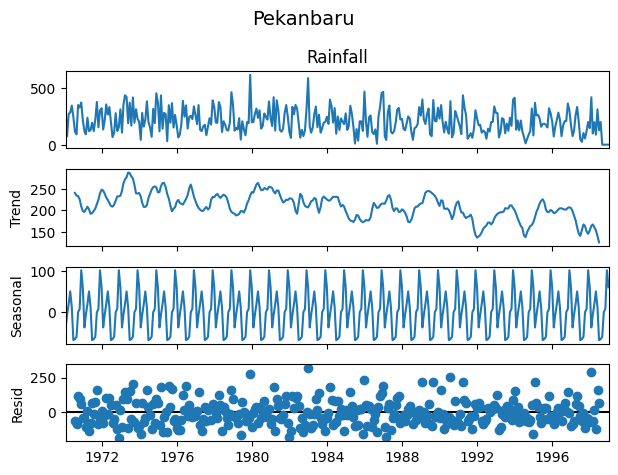

<ipython-input-30-47e2b21452c0>:10: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df = df['Rainfall'].resample('M').sum()


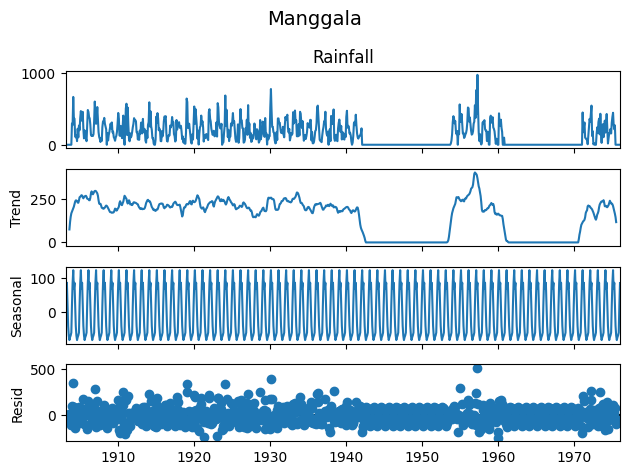

<ipython-input-30-47e2b21452c0>:10: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df = df['Rainfall'].resample('M').sum()


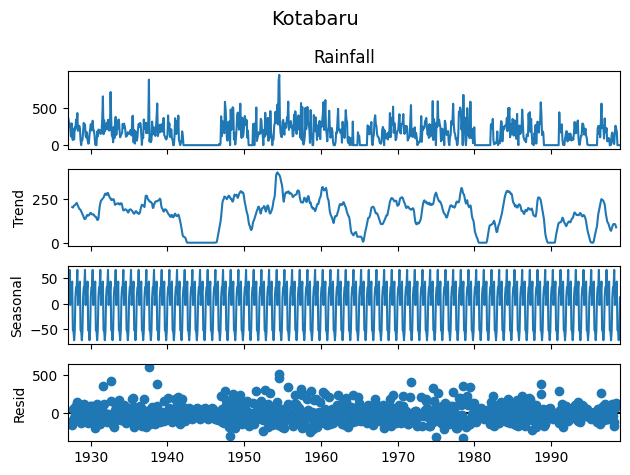

In [ ]:
# Pastikan data Date memiliki frekuensi waktu yang jelas
for name, df in zip(['Siak','Pekanbaru', 'Manggala', 'Kotabaru'], [df1_long, df2_long, df3_long,df4_long]):
    # Ubah kolom Date menjadi datetime jika belum
    df['Date'] = pd.to_datetime(df['Date'])

    # Setel 'Date' sebagai indeks
    df = df.set_index('Date')

    # Resample data untuk memastikan frekuensi bulanan (sum jika ada duplikasi)
    df = df['Rainfall'].resample('M').sum()

    # Decomposisi data
    decomposed = seasonal_decompose(df, model='additive', period=12)

    # Plot hasil dekomposisi
    decomposed.plot()
    plt.suptitle(f'{name}', fontsize=14)
    plt.tight_layout()
    plt.show()


## 3. Frequency

## 4. Monthly Heatmap

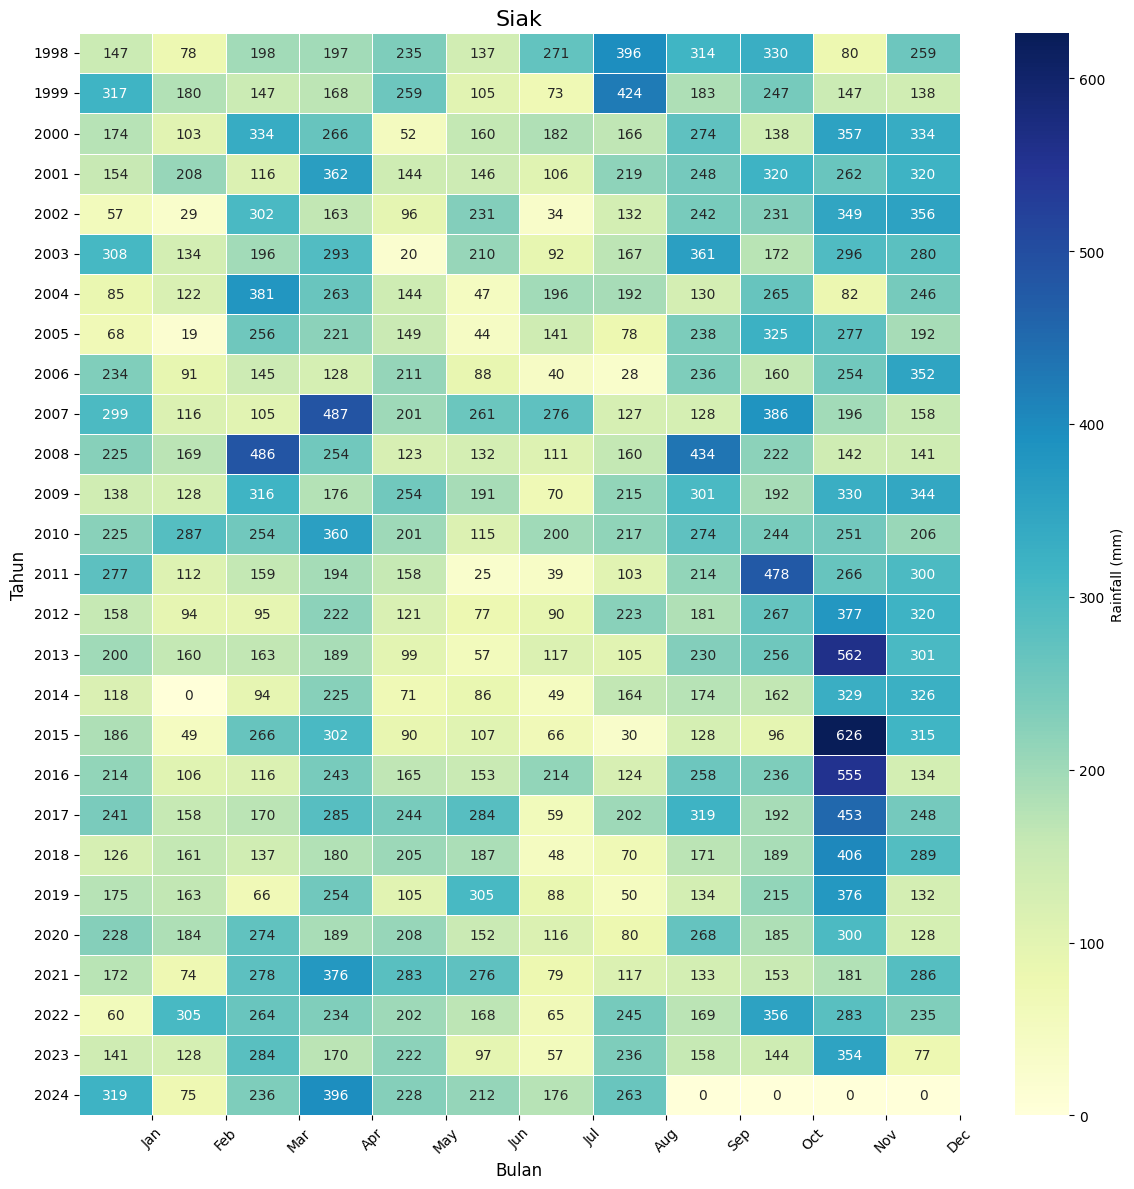

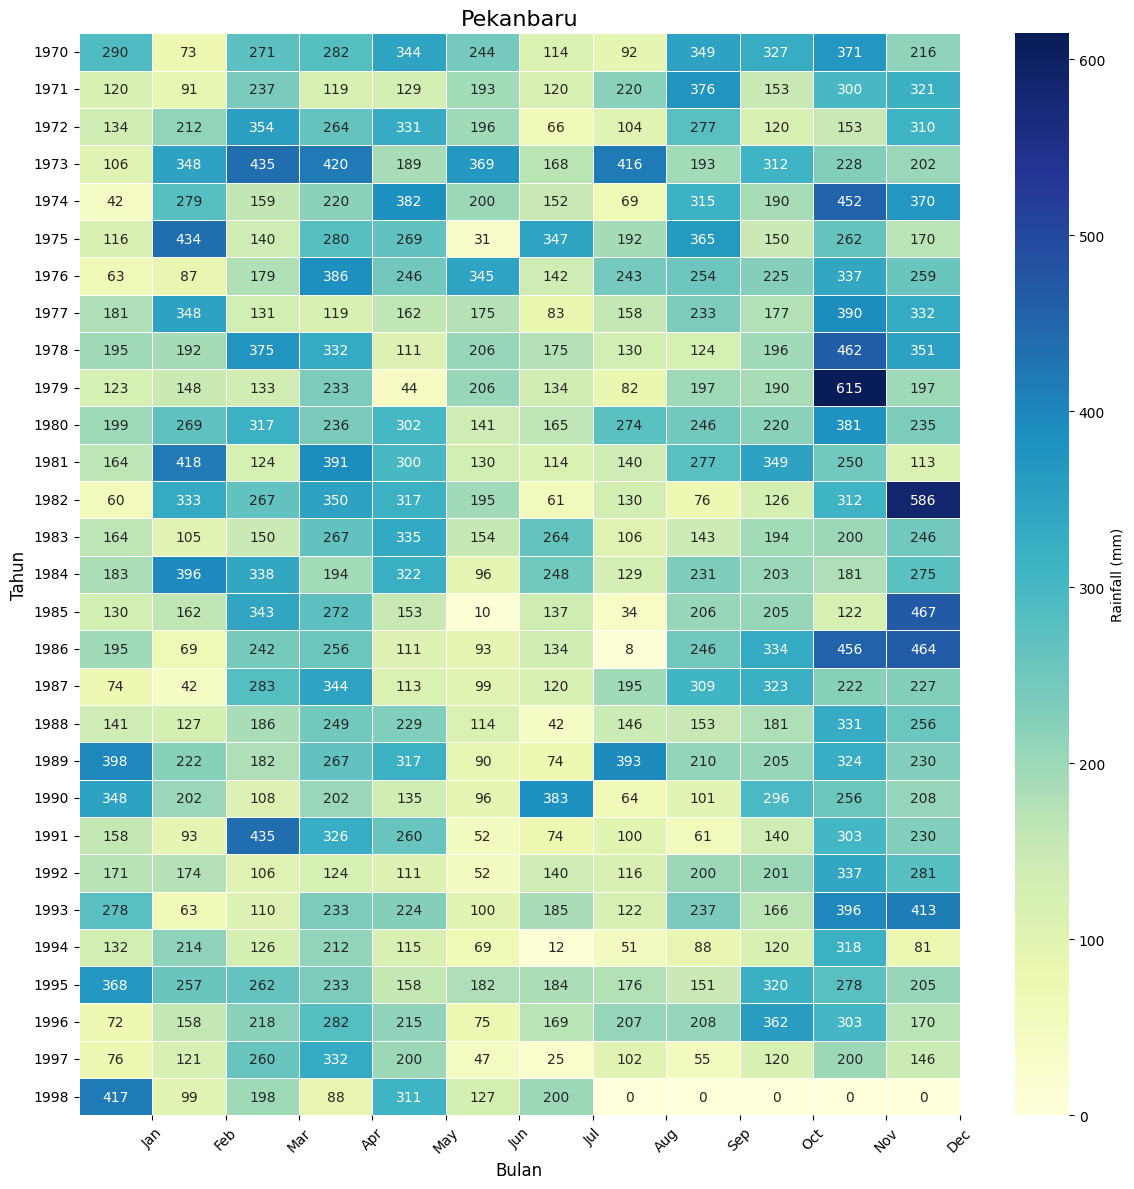

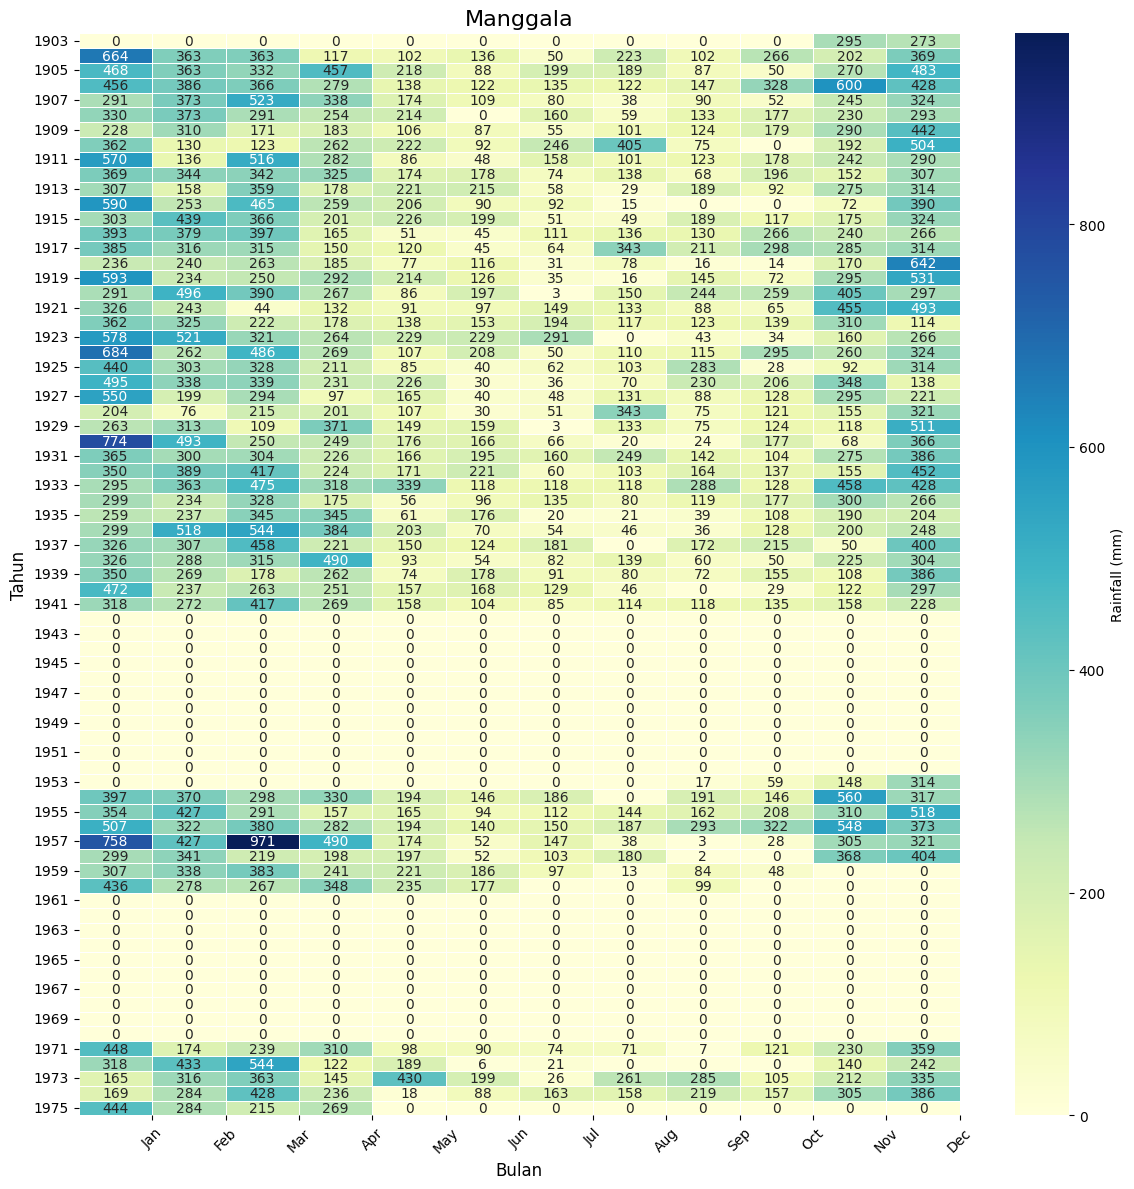

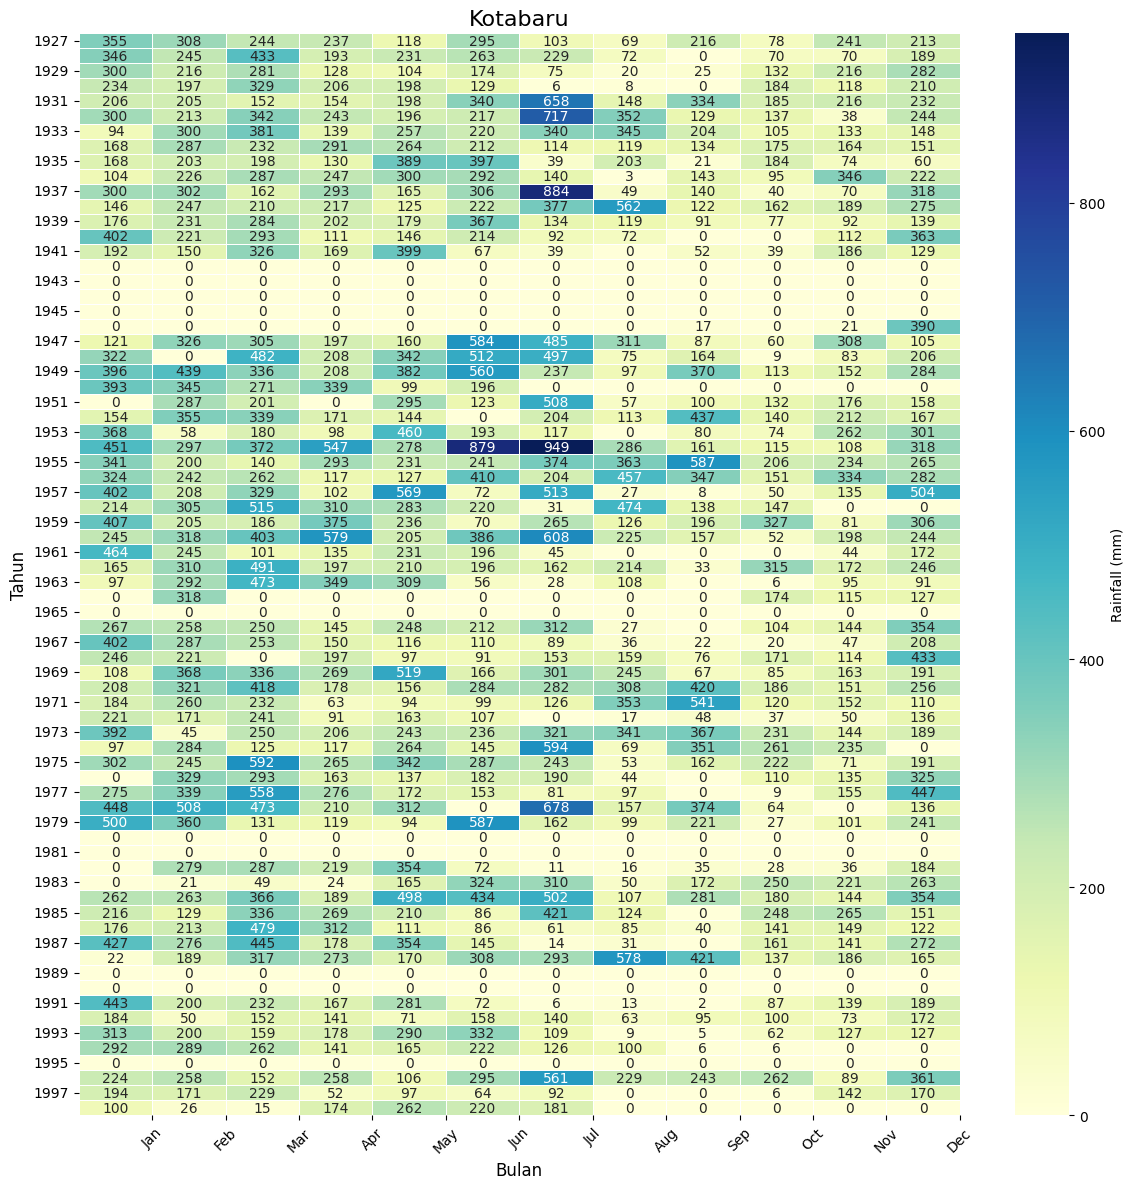

In [ ]:
# Loop untuk membuat heatmap untuk setiap lokasi
for name, df in zip(['Siak','Pekanbaru', 'Manggala', 'Kotabaru'], [df1_long, df2_long, df3_long, df4_long]):
    # Pastikan data 'Date' adalah format datetime
    df['Date'] = pd.to_datetime(df['Date'])

    # Menambahkan kolom Tahun dan Bulan
    df['Year'] = df['Date'].dt.year
    df['Month'] = df['Date'].dt.month

    # Mengelompokkan data untuk total curah hujan per tahun dan bulan
    heatmap_data = df.groupby(['Year', 'Month'])['Rainfall'].sum().unstack(fill_value=0)

    # Membuat heatmap
    plt.figure(figsize=(12, 12))
    sns.heatmap(
        heatmap_data,
        cmap='YlGnBu',
        annot=True,       # Menampilkan nilai pada heatmap
        fmt=".0f",        # Format angka
        linewidths=0.5,   # Jarak antar kotak heatmap
        cbar_kws={'label': 'Rainfall (mm)'}  # Label untuk colorbar
    )

    # Judul dan label
    plt.title(f'{name}', fontsize=16)
    plt.xlabel('Bulan', fontsize=12)
    plt.ylabel('Tahun', fontsize=12)

    # Menyesuaikan tampilan sumbu x dengan nama bulan
    months_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
    plt.xticks(ticks=range(1, 13), labels=months_labels, rotation=45)

    # Tampilkan heatmap
    plt.tight_layout()
    plt.show()


## 5. Correlation Plot

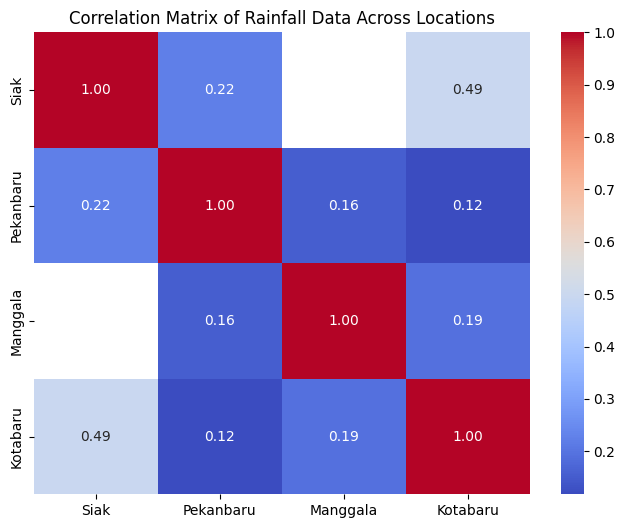

In [ ]:
# prompt: bisakah hitung korelasi antara lokasi?

# Concatenate the dataframes for correlation analysis
# Ensure 'Rainfall' column exists in all dataframes
dfs_for_correlation = []
for name, df in zip(['Siak', 'Pekanbaru', 'Manggala', 'Kotabaru'], [df1_long, df2_long, df3_long, df4_long]):
    df = df.rename(columns={'Rainfall': name})  # Rename 'Rainfall' column with location name
    # Select only 'Date' and the renamed 'Rainfall' column
    df = df[['Date', name]]
    dfs_for_correlation.append(df)

# Merge dataframes on 'Date'
merged_df = dfs_for_correlation[0]
for df in dfs_for_correlation[1:]:
    merged_df = pd.merge(merged_df, df, on='Date', how='outer')

# Select only numeric columns for correlation calculation
numeric_df = merged_df.select_dtypes(include='number')

# Calculate the correlation matrix for numeric columns
correlation_matrix = numeric_df.corr()

# Plot the correlation matrix as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Rainfall Data Across Locations')
plt.show()